# Formula 1 Podium Prediction : Milestone 1

**Goal:** for each driver in each race, predict whether he finishes on the **podium** (top 3), using only information known **after qualifying and before the race starts**.

**Data:** Kaggle *Formula 1 World Championship (1950–2024)* — 14 linked CSV tables.

### Notebook map (checklist)

| Section | Checklist items |
|---|---|
| 1. Setup & loading | run-all ready |
| 2. EDA **before** cleaning | EDA + plots |
| 3. Cleaning | `\N` sentinels, semantic typing, PK/FK checks, one row per (raceId, driverId) |
| 4. EDA **after** cleaning | impact of cleaning, data-analysis plots |
| 5. Data-engineering questions Q1–Q3 | answers + plots + markdown |
| 6. Features | leakage-safe form features, evidence + plots for each feature |
| 7. Train / validation / test split | justified split |
| 8. Pre-processing | effect on distribution, 2 preprocessing-order experiments |
| 9. Predictive models | 4 models on the same table, ROC-AUC / PR-AUC / F1 on validation and test |
| 10. Feature-group ablation | remove each feature group, retrain, report the drop |
| 11. Explainability (XAI) | permutation importance, SHAP (global), LIME or local SHAP (one row), causal caveat |
| 12. Inference function | demo on a complete record and a partially-missing record |
| 13. Analytical report | checklist of what goes into the PDF report |

## 1. Setup & loading

We import the libraries, fix a random seed (so every run gives the same numbers), and find the data folder automatically (Kaggle mounts it under `/kaggle/input/...`).

We load every CSV **as text** (`dtype=str`) so we can see the raw values exactly as they are in the file, including the `\N` placeholders. The `raw` tables are never changed — all cleaning is done on a copy.

In [46]:
import os, glob, warnings
warnings.filterwarnings("ignore")
# for pkg in ["shap", "lime"]:
#     try: __import__(pkg)
#     except ImportError: subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg])

import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from scipy.stats import spearmanr
import statsmodels.formula.api as smf
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score, precision_score, recall_score,
                             roc_curve, precision_recall_curve, ConfusionMatrixDisplay)
from sklearn.inspection import permutation_importance

SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid")
YEAR_MAX = 2024

# Data lives in dataset/archive relative to this notebook
DATA_DIR = os.path.join(os.path.dirname(os.path.abspath("__file__")), "dataset", "archive")
if not os.path.exists(os.path.join(DATA_DIR, "results.csv")):
    # Fallback: search common locations
    found = (glob.glob("./dataset/archive/results.csv") + glob.glob("./dataset/results.csv") + glob.glob("./data/results.csv") + glob.glob("./results.csv")
             + glob.glob("/kaggle/input/**/results.csv", recursive=True))  # Kaggle: attached datasets mount under /kaggle/input
    if not found:
        raise FileNotFoundError("Could not find results.csv. Place the dataset CSVs in the dataset/archive/ folder.")
    DATA_DIR = os.path.dirname(os.path.abspath(found[0]))
print("Data folder:", DATA_DIR)

TABLES = ["circuits", "constructors", "constructor_results", "constructor_standings", "drivers", "driver_standings",
          "races", "results", "qualifying", "lap_times", "pit_stops", "sprint_results", "seasons", "status"]
raw = {t: pd.read_csv(f"{DATA_DIR}/{t}.csv", dtype=str, keep_default_na=False) for t in TABLES}
pd.DataFrame({t: [len(df), df.shape[1]] for t, df in raw.items()}, index=["rows", "columns"]).T

Data folder: /home/abdelrahman/Documents/Uni Stuff/CSEN 903/Project/F1_AI_Tools/dataset/archive


,rows,columns
circuits,77,9
constructors,212,5
constructor_results,12625,5
constructor_standings,13391,7
drivers,861,9
driver_standings,34863,7
races,1125,18
results,26759,18
qualifying,10494,9
lap_times,589081,6


## 2. EDA before cleaning

### 2.1 Where are the missing values?
Ergast writes missing values as the text `\N`. We count them per column.

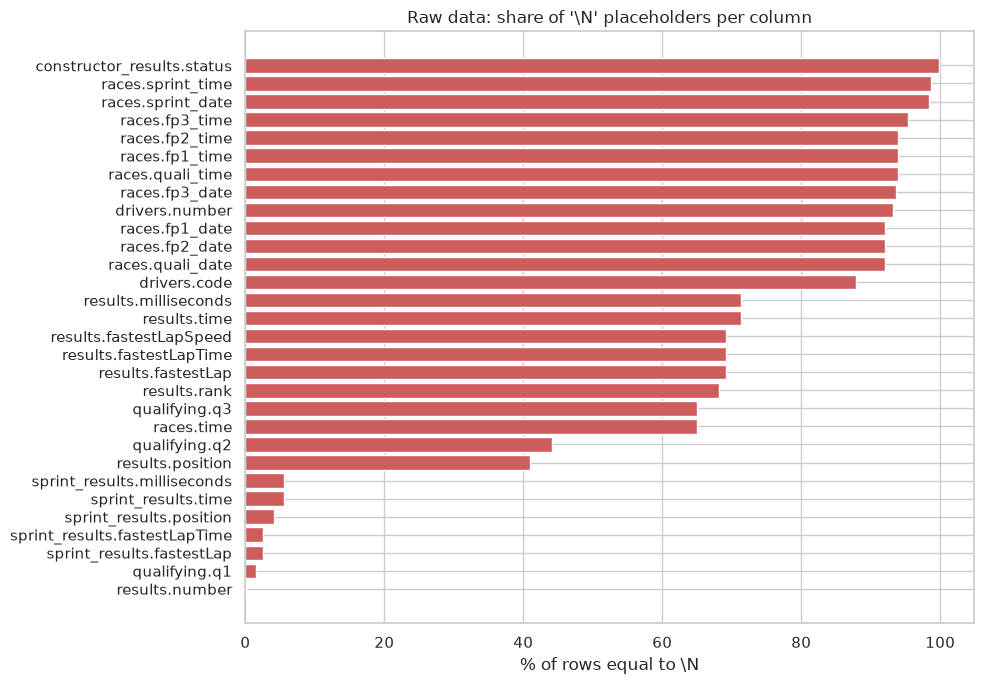

,column,pct_missing
0,constructor_results.status,99.9
13,races.sprint_time,98.7
12,races.sprint_date,98.4
9,races.fp3_time,95.3
7,races.fp2_time,94.0
5,races.fp1_time,94.0
11,races.quali_time,94.0
8,races.fp3_date,93.6
1,drivers.number,93.1
4,races.fp1_date,92.0


In [47]:
missing = []
for t, df in raw.items():
    for col in df.columns:
        share = (df[col] == "\\N").mean()
        if share > 0:
            missing.append({"column": f"{t}.{col}", "pct_missing": 100 * share})
missing = pd.DataFrame(missing).sort_values("pct_missing", ascending=False)

plt.figure(figsize=(10, 7))
plt.barh(missing.column, missing.pct_missing, color="indianred")
plt.gca().invert_yaxis(); plt.xlabel("% of rows equal to \\N")
plt.title("Raw data: share of '\\N' placeholders per column"); plt.tight_layout(); plt.show()
missing.head(10).round(1)

**What we see:** missing values are not random — they have a reason:
* `results.time`, `fastestLap…`: only finishers have a race time, and fastest-lap data only exists from 2004. These are **post-race** fields anyway, so we never use them as features.
* `results.position`: missing when the driver was not classified (crash, retirement). `positionOrder` is always filled, so we use it for the target.
* `qualifying.q2`, `q3`: drivers knocked out in Q1 have no Q2/Q3 time. So "missing" here means "eliminated early".
* `races.fp1_date …`: session times were only recorded for recent seasons.

### 2.2 Problem: numbers stored as text
If we load the files normally, any column that contains `\N` becomes a text column, so we cannot do maths on it.

In [48]:
naive = pd.read_csv(f"{DATA_DIR}/results.csv")
print("results columns loaded as text by a normal read:")
print([c for c in naive.columns if not pd.api.types.is_numeric_dtype(naive[c])])

results columns loaded as text by a normal read:
['number', 'position', 'positionText', 'time', 'milliseconds', 'fastestLap', 'rank', 'fastestLapTime', 'fastestLapSpeed']


### 2.3 How complete is the qualifying data over time?

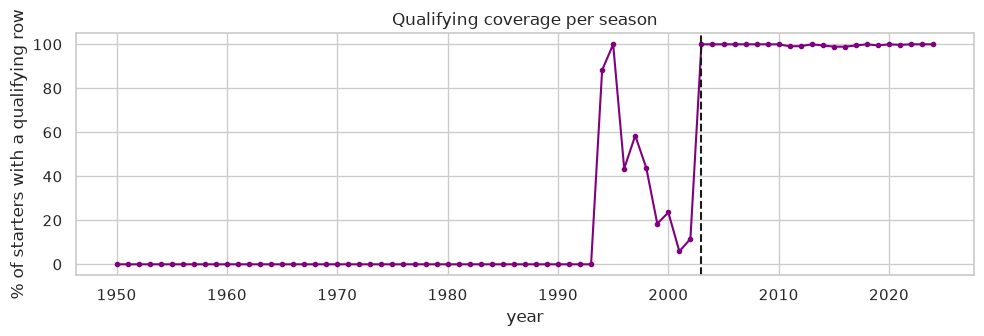

{1993: 0.0, 1994: 88.0, 1995: 100.0, 1996: 44.0, 1997: 59.0, 1998: 44.0, 1999: 18.0, 2000: 24.0, 2001: 6.0, 2002: 12.0, 2003: 100.0, 2004: 100.0}


In [49]:
years = raw["races"][["raceId", "year"]]
res_per_year = raw["results"].merge(years).year.astype(int).value_counts().sort_index()
q_per_year = raw["qualifying"].merge(years).year.astype(int).value_counts().reindex(res_per_year.index, fill_value=0)
coverage = (100 * q_per_year / res_per_year).loc[:YEAR_MAX]

coverage.plot(figsize=(10, 3.5), marker=".", color="purple")
plt.ylabel("% of starters with a qualifying row"); plt.title("Qualifying coverage per season")
plt.axvline(2003, ls="--", c="k"); plt.tight_layout(); plt.show()
print(coverage.loc[1993:2004].round(0).to_dict())

**Key finding:** qualifying data does not exist before 1994 and is very patchy between 1996 and 2002. It is complete only **from 2003**. We do **not** drop the earlier seasons: that would throw away about half of all driver-race rows. Instead the modeling table keeps **all seasons (1950–2024)**, the qualifying features stay missing where no qualifying row exists, and a `has_quali` flag tells the model which rows have them. Section 8.2 tests this choice against a 2003+-only training set.

### 2.4 Duplicate driver–race rows

duplicated (raceId, driverId) rows: 176


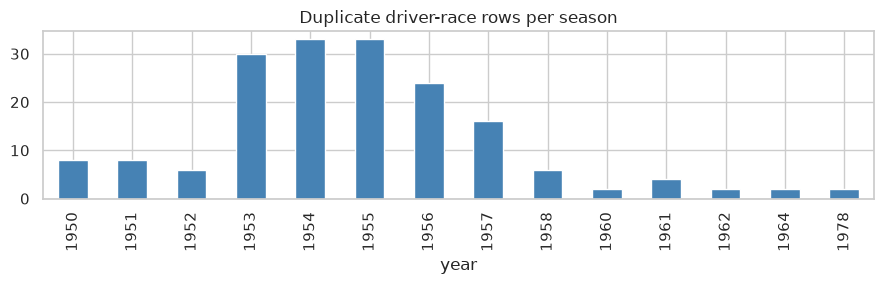

In [50]:
res_raw = raw["results"].merge(years)
dup = res_raw[res_raw.duplicated(["raceId", "driverId"], keep=False)]
print("duplicated (raceId, driverId) rows:", len(dup))
dup.year.astype(int).value_counts().sort_index().plot.bar(figsize=(9, 3), color="steelblue")
plt.title("Duplicate driver-race rows per season"); plt.tight_layout(); plt.show()

All duplicates are from the **1950s–60s "shared drives"**: a driver could take over a team-mate's car during the race, so he appears twice in the same race. We fix this in Section 3.

## 3. Data cleaning

### 3.1 Sentinels → real missing values
We replace every `\N` (and empty string) with a proper missing value `NaN`, on a **copy** of the data.

In [51]:
clean = {t: df.replace({"\\N": np.nan, "": np.nan}) for t, df in raw.items()}
print("remaining '\\N' cells:", sum(int((df == "\\N").sum().sum()) for df in clean.values()))

remaining '\N' cells: 0


### 3.2 Semantic typing
* **Numbers:** every column whose values are all numeric is converted to a number.
* **Dates:** `races.date` and `drivers.dob` become real dates.
* **Durations:** lap times like `"1:23.456"` become seconds (`83.456`). We check our converter against the `milliseconds` column that `lap_times` already has.

In [52]:
for t, df in clean.items():
    for col in df.columns:
        converted = pd.to_numeric(df[col], errors="coerce")
        if converted.notna().sum() == df[col].notna().sum():      # every non-missing value is a number
            df[col] = converted

clean["races"]["date"] = pd.to_datetime(clean["races"]["date"])
clean["drivers"]["dob"] = pd.to_datetime(clean["drivers"]["dob"])

def to_seconds(value):
    """'83.4' -> 83.4 ; '1:23.456' -> 83.456 ; missing/invalid -> NaN"""
    if pd.isna(value): return np.nan
    try:
        seconds = 0.0
        for part in str(value).split(":"):
            seconds = seconds * 60 + float(part)
        return seconds
    except ValueError:
        return np.nan

for q in ["q1", "q2", "q3"]:
    clean["qualifying"][q + "_sec"] = clean["qualifying"][q].map(to_seconds)
clean["pit_stops"]["duration_sec"] = clean["pit_stops"]["duration"].map(to_seconds)
clean["lap_times"]["time_sec"] = clean["lap_times"]["time"].map(to_seconds)

err = (clean["lap_times"].time_sec * 1000 - clean["lap_times"].milliseconds).abs().max()
print(f"check: max difference between our seconds and the milliseconds column = {err:.1f} ms")
clean["qualifying"][["q1", "q1_sec", "q3", "q3_sec"]].dropna().head(3)

check: max difference between our seconds and the milliseconds column = 0.0 ms


,q1,q1_sec,q3,q3_sec
0,1:26.572,86.572,1:26.714,86.714
1,1:26.103,86.103,1:26.869,86.869
2,1:25.664,85.664,1:27.079,87.079


The difference is at most 1 ms (rounding), so the converter works.

### 3.3 Fixing inconsistent labels
`circuits.country` uses both `"USA"` and `"United States"`, and one nationality has a trailing space. We unify them, otherwise the home-race question (Q2) would be wrong.

In [53]:
clean["circuits"]["country"] = clean["circuits"]["country"].replace({"United States": "USA"})
clean["drivers"]["nationality"] = clean["drivers"]["nationality"].str.strip().replace({"Argentinian": "Argentine"})

### 3.4 Primary-key and foreign-key checks
* **Primary key (PK):** the column that identifies a row must be unique and never missing.
* **Foreign key (FK):** every ID that points to another table must exist in that table (otherwise joins silently lose rows).

In [54]:
PK = {"circuits": ["circuitId"], "constructors": ["constructorId"], "drivers": ["driverId"], "races": ["raceId"],
      "status": ["statusId"], "results": ["resultId"], "qualifying": ["qualifyId"],
      "driver_standings": ["driverStandingsId"], "constructor_standings": ["constructorStandingsId"],
      "lap_times": ["raceId", "driverId", "lap"], "pit_stops": ["raceId", "driverId", "stop"]}
pk_check = pd.DataFrame([{"table": t, "key": "+".join(k), "missing": int(clean[t][k].isna().any(axis=1).sum()),
                          "duplicates": int(clean[t].duplicated(k).sum())} for t, k in PK.items()])

FK = [("results", "raceId", "races"), ("results", "driverId", "drivers"), ("results", "constructorId", "constructors"),
      ("results", "statusId", "status"), ("qualifying", "raceId", "races"), ("qualifying", "driverId", "drivers"),
      ("races", "circuitId", "circuits"), ("driver_standings", "raceId", "races"), ("driver_standings", "driverId", "drivers"),
      ("constructor_standings", "raceId", "races"), ("lap_times", "raceId", "races"), ("pit_stops", "raceId", "races")]
fk_check = pd.DataFrame([{"foreign key": f"{child}.{col} -> {parent}",
                          "orphans": int((~clean[child][col].dropna().isin(clean[parent][col])).sum())} for child, col, parent in FK])
display(pk_check); display(fk_check)

,table,key,missing,duplicates
0,circuits,circuitId,0,0
1,constructors,constructorId,0,0
2,drivers,driverId,0,0
3,races,raceId,0,0
4,status,statusId,0,0
5,results,resultId,0,0
6,qualifying,qualifyId,0,0
7,driver_standings,driverStandingsId,0,0
8,constructor_standings,constructorStandingsId,0,0
9,lap_times,raceId+driverId+lap,0,0


,foreign key,orphans
0,results.raceId -> races,0
1,results.driverId -> drivers,0
2,results.constructorId -> constructors,0
3,results.statusId -> status,0
4,qualifying.raceId -> races,0
5,qualifying.driverId -> drivers,0
6,races.circuitId -> circuits,0
7,driver_standings.raceId -> races,0
8,driver_standings.driverId -> drivers,0
9,constructor_standings.raceId -> races,0


All primary keys are unique and complete, and all foreign keys match (0 orphans), so joins are safe.

### 3.5 One row per (raceId, driverId)
**Rule:** for a shared drive we keep the row with the driver's **best finishing position** (`positionOrder`).
**Why:** the target asks "did this driver finish on the podium?", and the official record credits the driver with his best result. Keeping a random or the first row could give the wrong label.

We also remove entries that **never started** (did not qualify / did not pre-qualify / 107% rule): after qualifying we already know they will not race, so they are not real prediction cases.

In [55]:
res = clean["results"].merge(clean["races"][["raceId", "year"]], on="raceId")
res = res[res.year <= YEAR_MAX]
before = len(res)
res = res.sort_values("positionOrder").drop_duplicates(["raceId", "driverId"], keep="first")
assert not res.duplicated(["raceId", "driverId"]).any()
print(f"rows: {before} -> {len(res)}  (removed {before - len(res)} duplicate rows)")

res["status"] = res.statusId.map(clean["status"].set_index("statusId").status)
res = res[~res.status.isin(["Did not qualify", "Did not prequalify", "107% Rule"])]
res["podium"] = (res.positionOrder <= 3).astype(int)
res["dnf"] = (~(res.status.eq("Finished") | res.status.str.startswith("+"))).astype(int)
print("race starters:", len(res), "| podium rate:", round(res.podium.mean(), 3))

rows: 26759 -> 26668  (removed 91 duplicate rows)
race starters: 25305 | podium rate: 0.134


## 4. EDA after cleaning

### 4.1 Impact of cleaning

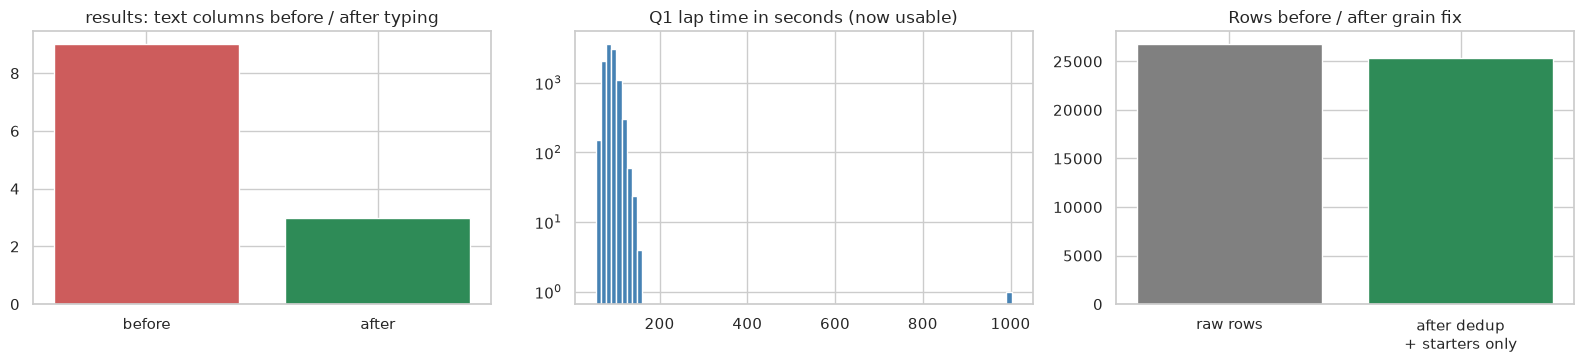

In [56]:
text_before = sum(not pd.api.types.is_numeric_dtype(naive[c]) for c in naive.columns)
text_after = sum(not pd.api.types.is_numeric_dtype(clean["results"][c]) for c in clean["results"].columns)
fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
ax[0].bar(["before", "after"], [text_before, text_after], color=["indianred", "seagreen"])
ax[0].set_title("results: text columns before / after typing")
ax[1].hist(clean["qualifying"].q1_sec.dropna(), bins=80, color="steelblue"); ax[1].set_yscale("log")
ax[1].set_title("Q1 lap time in seconds (now usable)")
ax[2].bar(["raw rows", "after dedup\n+ starters only"], [before, len(res)], color=["grey", "seagreen"])
ax[2].set_title("Rows before / after grain fix"); plt.tight_layout(); plt.show()

After cleaning, the numeric columns are real numbers, lap times can be compared, and each driver appears once per race. The Q1 histogram has several bumps because circuits have different lengths (60 s to 105 s) → we will use the **gap to the fastest driver in %**, not the raw time.

### 4.2 Building the master table (multi-table join)
`results` → `races` (year, date, circuit) → `circuits` (country) → `drivers` (birth date, nationality) → `constructors` (team name).

In [57]:
races = clean["races"][["raceId", "round", "circuitId", "name", "date"]].rename(columns={"name": "race_name"})
circuits = clean["circuits"][["circuitId", "name", "country"]].rename(columns={"name": "circuit"})
drivers = clean["drivers"][["driverId", "forename", "surname", "dob", "nationality"]]
teams = clean["constructors"][["constructorId", "name"]].rename(columns={"name": "team"})

df = (res.merge(races, on="raceId").merge(circuits, on="circuitId")
         .merge(drivers, on="driverId").merge(teams, on="constructorId"))
assert len(df) == len(res)
df["driver"] = df.forename + " " + df.surname
df = df.sort_values(["date", "positionOrder"]).reset_index(drop=True)
df[["year", "race_name", "driver", "team", "grid", "positionOrder", "status", "podium"]].tail(3)

,year,race_name,driver,team,grid,positionOrder,status,podium
25302,2024,Abu Dhabi Grand Prix,Valtteri Bottas,Sauber,9,18,Collision damage,0
25303,2024,Abu Dhabi Grand Prix,Franco Colapinto,Williams,20,19,Engine,0
25304,2024,Abu Dhabi Grand Prix,Sergio Pérez,Red Bull,10,20,Collision,0


### 4.3 Class balance and the effect of the starting position

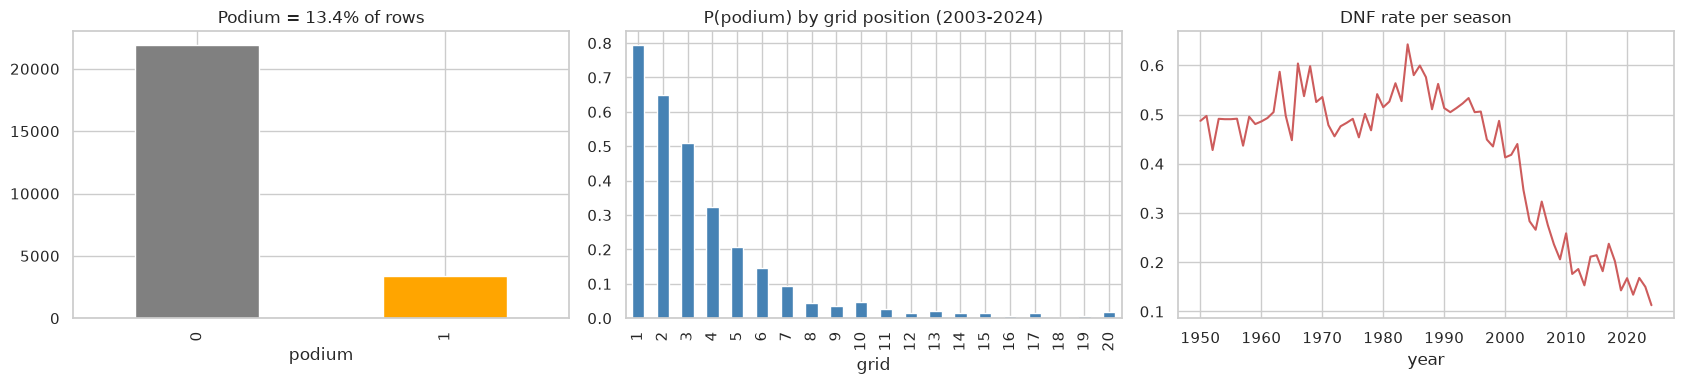

In [58]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
df.podium.value_counts().plot.bar(ax=ax[0], color=["grey", "orange"]); ax[0].set_title(f"Podium = {df.podium.mean():.1%} of rows")
d = df[(df.year >= 2003) & df.grid.between(1, 20)]
d.groupby("grid").podium.mean().plot.bar(ax=ax[1], color="steelblue"); ax[1].set_title("P(podium) by grid position (2003-2024)")
df.groupby("year").dnf.mean().plot(ax=ax[2], color="indianred"); ax[2].set_title("DNF rate per season")
plt.tight_layout(); plt.show()

* Only ~13–14 % of rows are podiums → the classes are **imbalanced**. Accuracy would be misleading (always saying "no" gives 86 %), so we use **PR-AUC** as our main metric later.
* The grid position is the strongest signal: pole ≈ 70–80 % podium, P10 almost never. The curve is **not a straight line** → non-linear models should help.
* Cars got much more reliable (DNF rate fell from ~50 % to ~15 %).

## 5. Data-engineering questions

### Q1 — Which circuits convert a front-row start into a podium most often? Does it change after 2014?

**Tables joined:** `results` + `races` + `circuits` + `qualifying`.
**Front row** = starting position 1 or 2. We compute it two ways: by **grid** (where the car actually started, after penalties) and by **qualifying position** (before penalties).
**Period:** 2003–2024 (qualifying complete), split into **2003–2013** vs **2014–2024** (hybrid era). Circuits need at least 10 front-row starts in a period to be ranked.

Overall conversion by grid: {'2003-2013': 0.68, '2014-2024': 0.76}
Overall conversion by qualifying: {'2003-2013': 0.672, '2014-2024': 0.737}


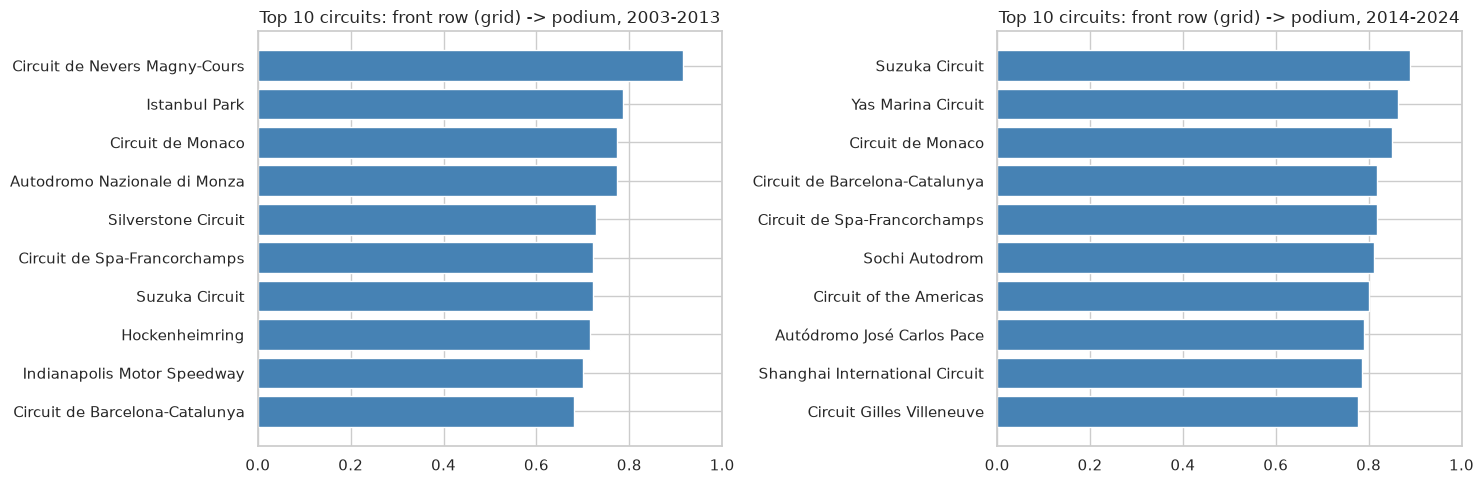

Ranking similarity between eras (Spearman rho) = 0.30, p = 0.29, circuits = 14


,circuit,era,rate_grid,starts_grid,rate_quali,starts_quali,difference
6,Autódromo José Carlos Pace,2014-2024,0.79,19,0.65,20,0.14
14,Circuit de Monaco,2003-2013,0.77,22,0.68,22,0.09
9,Baku City Circuit,2014-2024,0.62,16,0.69,16,-0.06
4,Autódromo Hermanos Rodríguez,2014-2024,0.61,18,0.56,18,0.06
11,Circuit Gilles Villeneuve,2014-2024,0.78,18,0.72,18,0.06


In [59]:
qual = clean["qualifying"].sort_values("position").drop_duplicates(["raceId", "driverId"])[["raceId", "driverId", "position", "q1_sec", "q2_sec", "q3_sec"]]
qual = qual.rename(columns={"position": "quali_pos"})
q1 = df[df.year >= 2003].merge(qual, on=["raceId", "driverId"], how="left")
q1["era"] = np.where(q1.year >= 2014, "2014-2024", "2003-2013")

def conversion(col):
    front = q1[q1[col].isin([1, 2])]
    t = front.groupby(["circuit", "era"]).podium.agg(rate="mean", starts="size").reset_index()
    return t[t.starts >= 10]

by_grid, by_quali = conversion("grid"), conversion("quali_pos")
print("Overall conversion by grid:", q1[q1.grid.isin([1, 2])].groupby("era").podium.mean().round(3).to_dict())
print("Overall conversion by qualifying:", q1[q1.quali_pos.isin([1, 2])].groupby("era").podium.mean().round(3).to_dict())

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
for a, era in zip(ax, ["2003-2013", "2014-2024"]):
    top = by_grid[by_grid.era == era].sort_values("rate").tail(10)
    a.barh(top.circuit, top.rate, color="steelblue"); a.set_xlim(0, 1)
    a.set_title(f"Top 10 circuits: front row (grid) -> podium, {era}")
plt.tight_layout(); plt.show()

wide = by_grid.pivot(index="circuit", columns="era", values="rate").dropna()
rho = spearmanr(wide["2003-2013"], wide["2014-2024"])
print(f"Ranking similarity between eras (Spearman rho) = {rho.statistic:.2f}, p = {rho.pvalue:.2f}, circuits = {len(wide)}")
comp = by_grid.merge(by_quali, on=["circuit", "era"], suffixes=("_grid", "_quali"))
comp["difference"] = comp.rate_grid - comp.rate_quali
comp.sort_values("difference", key=abs, ascending=False).head(5).round(2)

**Answer Q1.**
* Front-row starters reached the podium **68 %** of the time in 2003–2013 and **76 %** in 2014–2024: the dominant hybrid-era teams (Mercedes, then Red Bull) converted front rows very reliably.
* The bar charts show the top 10 circuits in each era. The Spearman correlation between the two rankings is only **ρ ≈ 0.30 (p ≈ 0.29, 14 circuits)** — weak and not significant, so **the ranking changes after 2014**. Conversion depends more on the era's competitive order than on the track itself.
* **Grid vs qualifying:** by qualifying position the hybrid-era conversion is 73.7 % instead of 76 %. The table shows the circuits where the definitions differ most (e.g. Interlagos 2014–2024: 79 % by grid vs 65 % by qualifying). They differ because of grid penalties: a driver can qualify on the front row but start further back.
* *Grain:* one row per driver-race. *Missing values:* rows without a qualifying record are excluded only from the qualifying definition. *Cutoff:* grid and qualifying position are both known before the race.

### Q2 — Do drivers podium more often at home, after controlling for starting position?

**Tables joined:** `results` + `drivers` (nationality) + `races` + `circuits` (country). We map nationality → country (e.g. *British* → *UK*).
**Controlling for starting position:** we compare home and away drivers **inside the same grid bucket** (P1, P2–3, P4–6, …). Then we fit a logistic regression `podium ~ home + grid bucket + decade`. The coefficient of `home` is the home effect *at the same starting position*.

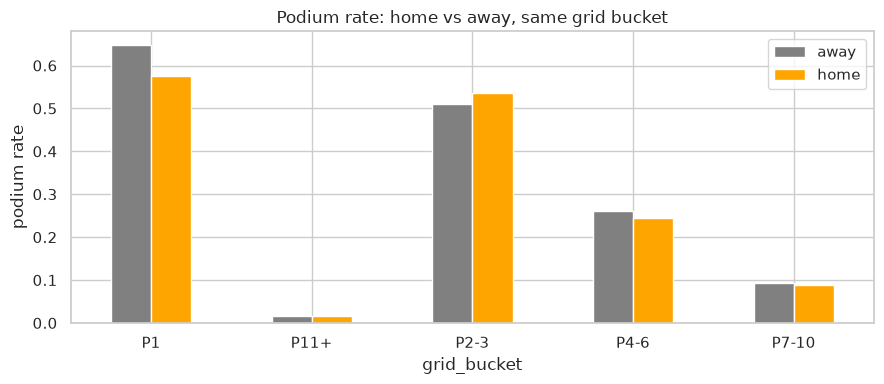

Raw podium rate: home 0.115 vs away 0.138
Home odds ratio controlling for grid & decade = 0.92  (95% CI 0.78-1.08, p = 0.29)


In [60]:
NAT = {"British": "UK", "German": "Germany", "East German": "Germany", "Italian": "Italy", "French": "France",
       "Spanish": "Spain", "Brazilian": "Brazil", "American": "USA", "American-Italian": "USA", "Argentine": "Argentina",
       "Argentine-Italian": "Argentina", "Australian": "Australia", "Austrian": "Austria", "Belgian": "Belgium",
       "Canadian": "Canada", "Dutch": "Netherlands", "Finnish": "Finland", "Japanese": "Japan", "Mexican": "Mexico",
       "Monegasque": "Monaco", "Swiss": "Switzerland", "Swedish": "Sweden", "Russian": "Russia", "Portuguese": "Portugal",
       "South African": "South Africa", "Hungarian": "Hungary", "Chinese": "China", "Indian": "India",
       "Malaysian": "Malaysia", "Thai": "Thailand", "Danish": "Denmark", "New Zealander": "New Zealand"}
df["home_race"] = (df.nationality.map(NAT) == df.country).astype(int)

q2 = df[df.grid > 0].copy()
q2["grid_bucket"] = pd.cut(q2.grid, [0, 1, 3, 6, 10, 99], labels=["P1", "P2-3", "P4-6", "P7-10", "P11+"]).astype(str)
q2["decade"] = (q2.year // 10 * 10).astype(str)

rates = q2.groupby(["grid_bucket", "home_race"]).podium.mean().unstack()
rates.columns = ["away", "home"]
rates.plot.bar(figsize=(9, 4), color=["grey", "orange"], rot=0); plt.ylabel("podium rate")
plt.title("Podium rate: home vs away, same grid bucket"); plt.tight_layout(); plt.show()

model = smf.logit("podium ~ home_race + C(grid_bucket) + C(decade)", data=q2).fit(disp=0)
odds = np.exp(model.params["home_race"]); lo, hi = np.exp(model.conf_int().loc["home_race"])
print(f"Raw podium rate: home {q2[q2.home_race==1].podium.mean():.3f} vs away {q2[q2.home_race==0].podium.mean():.3f}")
print(f"Home odds ratio controlling for grid & decade = {odds:.2f}  (95% CI {lo:.2f}-{hi:.2f}, p = {model.pvalues['home_race']:.2f})")

**Answer Q2. No home advantage.** Without any control, home drivers actually podium *less* (11.5 % vs 13.8 %). Inside each grid bucket the home and away rates are similar. The controlled odds ratio is **0.92 (95 % CI 0.78–1.08, p ≈ 0.29)**: the interval contains 1, so after controlling for starting position there is **no evidence that racing at home helps**.
* *Grain:* driver-race starters with a grid slot (`grid > 0`). *Missing:* rows with `grid = 0` are excluded (no starting position to control for). *Cutoff:* nationality, circuit country and grid are all pre-race, so `home_race` is a legal feature.
* *Caution:* this is an association, not a cause. Nationality is only a rough proxy for "home".

### Q3 — Which constructors have the highest mechanical-retirement rate, 2014–2021 vs 2022–2024?

**Tables joined:** `results` + `status` + `constructors` + `races`.
**Mechanical retirement** = the race ended because a car part failed. We list those statuses explicitly (engine, gearbox, brakes, hydraulics…). Crashes (*Accident, Collision, Spun off*), driver/medical reasons and regulation decisions (*Disqualified*) are **not** mechanical.
**Rate** = mechanical retirements ÷ race starts, per team and period (teams with at least 20 starts).

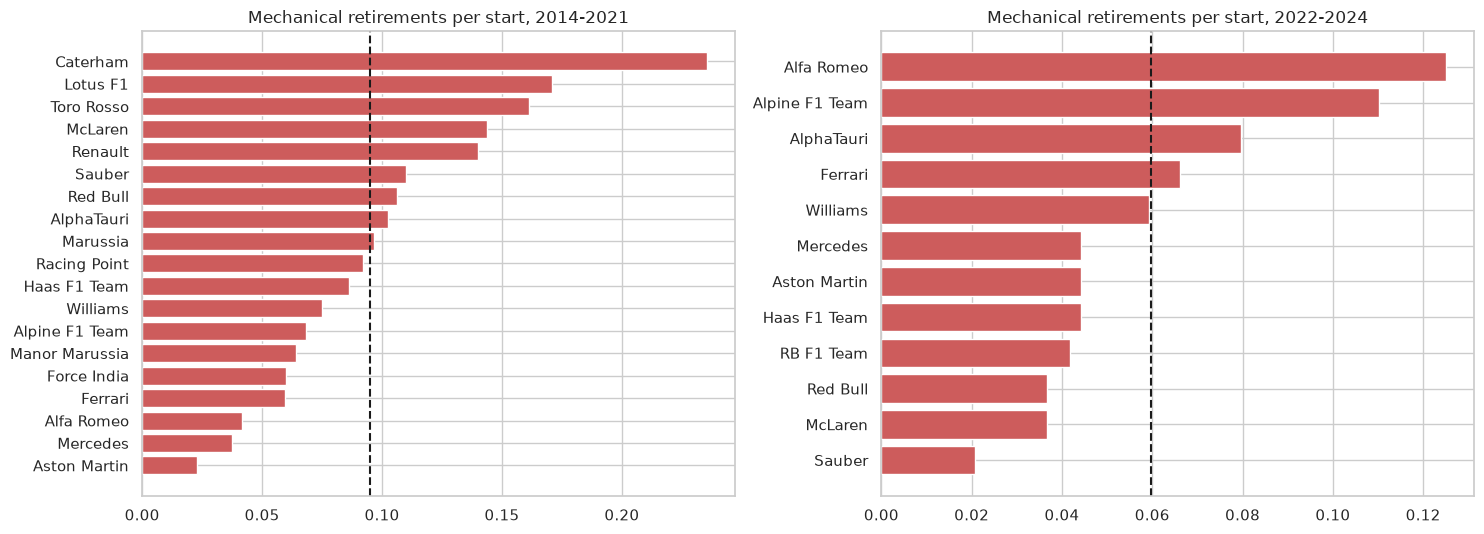

Overall rate: {'2014-2021': 0.095, '2022-2024': 0.06}
2014-2021 top 3: [['Caterham', 0.235, 34], ['Lotus F1', 0.171, 76], ['Toro Rosso', 0.161, 242]]
2022-2024 top 3: [['Alfa Romeo', 0.125, 88], ['Alpine F1 Team', 0.11, 136], ['AlphaTauri', 0.08, 88]]


In [61]:
MECHANICAL = {"Engine", "Gearbox", "Transmission", "Clutch", "Hydraulics", "Electrical", "Radiator", "Suspension", "Brakes",
              "Differential", "Overheating", "Mechanical", "Driveshaft", "Fuel pressure", "Water pressure", "Wheel", "Throttle",
              "Steering", "Technical", "Electronics", "Exhaust", "Oil leak", "Water leak", "Fuel pump", "Oil pressure",
              "Engine fire", "Pneumatics", "Wheel bearing", "Fuel system", "Power loss", "Vibrations", "Drivetrain", "Battery",
              "Turbo", "Water pump", "Power Unit", "ERS", "Cooling system", "Brake duct", "Undertray", "Fuel leak", "Oil line"}
q3 = df[df.year >= 2014].copy()
q3["period"] = np.where(q3.year <= 2021, "2014-2021", "2022-2024")
q3["mechanical"] = q3.status.isin(MECHANICAL).astype(int)
mech = q3.groupby(["period", "team"]).mechanical.agg(rate="mean", starts="size").reset_index()
mech = mech[mech.starts >= 20]

fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))
for a, p in zip(ax, ["2014-2021", "2022-2024"]):
    t = mech[mech.period == p].sort_values("rate")
    a.barh(t.team, t.rate, color="indianred"); a.axvline(q3[q3.period == p].mechanical.mean(), c="k", ls="--")
    a.set_title(f"Mechanical retirements per start, {p}")
plt.tight_layout(); plt.show()
print("Overall rate:", q3.groupby("period").mechanical.mean().round(3).to_dict())
for p in ["2014-2021", "2022-2024"]:
    print(p, "top 3:", mech[mech.period == p].nlargest(3, "rate")[["team", "rate", "starts"]].round(3).values.tolist())

**Answer Q3.**
* **2014–2021** (average 9.5 % of starts): highest rates for **Caterham (23.5 %)**, **Lotus F1 (17.1 %)** and **Toro Rosso (16.1 %)**, followed by McLaren in its Honda years.
* **2022–2024** (average 6.0 %, cars became more reliable): highest for **Alfa Romeo (12.5 %)**, **Alpine (11.0 %)** and **AlphaTauri (8.0 %)**.
* With only ~60–140 starts per team in 2022–2024, small differences between teams are not significant.
* *Grain:* one row per driver-race start. *Cutoff:* `status` is **post-race** information, so this is only a descriptive analysis — it is never used as a feature.

## 6. Feature engineering

### 6.1 Which fields would be leakage?
**Leakage** = using information that is only known *after* the race starts. Allowed vs. not allowed:

| ❌ Not allowed (future) | ✅ Allowed (known before the start) |
|---|---|
| `positionOrder`, `position`, `points`, `laps`, `time`, `fastestLap`, `status` of **this** race | `grid`, qualifying position and lap times |
| lap times / pit stops of **this** race | results of **previous** races (form) |
| standings **after** this race (`driver_standings` with this raceId) | standings after the **previous** round |
| | driver age, nationality, circuit, team |

### 6.2 Our features (6 groups)

| Group | Feature | Meaning |
|---|---|---|
| grid | `grid` | starting slot (pit-lane start = back of the grid) |
| grid | `pitlane_start` | 1 if the car started from the pit lane |
| qualifying | `quali_pos` | qualifying position |
| qualifying | `quali_gap_pct` | gap to the fastest qualifier, in % |
| qualifying | `has_quali` | 1 if a qualifying result exists for this entry (0 for most races before 2003) |
| driver form | `drv_podiums_last5` | share of podiums in the driver's previous 5 races |
| driver form | `drv_avg_finish_last5` | average finishing position in previous 5 races |
| team form | `team_podiums_last5` | average podiums per race for the team, previous 5 races |
| standings | `drv_points_share` | driver's points ÷ leader's points before this race |
| standings | `drv_champ_pos` | driver's championship position before this race |
| standings | `team_champ_pos` | team's championship position before this race |
| context | `driver_age` | age on race day |
| context | `home_race` | 1 if the race is in the driver's country |

**Leakage-safe form features:** we sort each driver's races by date and use `shift(1)` **before** the rolling average. `shift(1)` moves everything down one race, so the value for a race only uses races **before** it.

In [62]:
df = df.sort_values(["date", "raceId"]).reset_index(drop=True)
df["field_size"] = df.groupby("raceId").driverId.transform("size")

# grid
df["pitlane_start"] = (df.grid == 0).astype(int)
df["grid_feat"] = np.where(df.grid > 0, df.grid, df.field_size)

# qualifying
qual["best_q"] = qual[["q1_sec", "q2_sec", "q3_sec"]].min(axis=1)
qual["quali_gap_pct"] = (100 * (qual.best_q / qual.groupby("raceId").best_q.transform("min") - 1)).clip(upper=10)
df = df.merge(qual[["raceId", "driverId", "quali_pos", "quali_gap_pct"]], on=["raceId", "driverId"], how="left")
df["has_quali"] = df.quali_pos.notna().astype(int)   # qualifying data is missing for most pre-2003 races

# driver form: only PAST races (shift(1) then rolling)
by_driver = df.groupby("driverId")
df["drv_podiums_last5"] = by_driver.podium.transform(lambda s: s.shift(1).rolling(5, min_periods=1).mean())
df["drv_avg_finish_last5"] = by_driver.positionOrder.transform(lambda s: s.shift(1).rolling(5, min_periods=1).mean())

# team form: podiums per race for the team, then shift(1) + rolling over the team's past races
team_race = df.groupby(["constructorId", "raceId", "date"], as_index=False).podium.sum().sort_values("date")
team_race["team_podiums_last5"] = team_race.groupby("constructorId").podium.transform(lambda s: s.shift(1).rolling(5, min_periods=1).mean())
df = df.merge(team_race[["constructorId", "raceId", "team_podiums_last5"]], on=["constructorId", "raceId"], how="left")

# standings after the PREVIOUS round of the same season
rr = clean["races"][["raceId", "year", "round"]]
prev = rr.assign(round=rr["round"] + 1).rename(columns={"raceId": "prev_raceId"})
df = df.merge(prev, on=["year", "round"], how="left")
ds = clean["driver_standings"][["raceId", "driverId", "points", "position"]].rename(columns={"raceId": "prev_raceId", "points": "drv_pts", "position": "drv_champ_pos"})
ds["leader_pts"] = ds.groupby("prev_raceId").drv_pts.transform("max")
cs = clean["constructor_standings"][["raceId", "constructorId", "position"]].rename(columns={"raceId": "prev_raceId", "position": "team_champ_pos"})
df = df.merge(ds, on=["prev_raceId", "driverId"], how="left").merge(cs, on=["prev_raceId", "constructorId"], how="left")
df["drv_points_share"] = (df.drv_pts / df.leader_pts.replace(0, np.nan)).fillna(0)

# context
df["driver_age"] = (df.date - df.dob).dt.days / 365.25

GROUPS = {"grid": ["grid_feat", "pitlane_start"], "qualifying": ["quali_pos", "quali_gap_pct", "has_quali"],
          "driver_form": ["drv_podiums_last5", "drv_avg_finish_last5"], "team_form": ["team_podiums_last5"],
          "standings": ["drv_points_share", "drv_champ_pos", "team_champ_pos"], "context": ["driver_age", "home_race"]}
FEATURES = [f for g in GROUPS.values() for f in g]
print(len(FEATURES), "features:", FEATURES)

13 features: ['grid_feat', 'pitlane_start', 'quali_pos', 'quali_gap_pct', 'has_quali', 'drv_podiums_last5', 'drv_avg_finish_last5', 'team_podiums_last5', 'drv_points_share', 'drv_champ_pos', 'team_champ_pos', 'driver_age', 'home_race']


### 6.3 Test: does the form feature really use only past races?
For 100 random rows we recompute `drv_podiums_last5` by hand, using only races with an **earlier date**, and check that it matches.

In [63]:
mismatches = 0
for _, row in df.sample(100, random_state=SEED).iterrows():
    past = df[(df.driverId == row.driverId) & (df.date < row.date)].sort_values("date")
    expected = past.podium.tail(5).mean() if len(past) else np.nan
    if not (np.isclose(expected, row.drv_podiums_last5) or (np.isnan(expected) and np.isnan(row.drv_podiums_last5))):
        mismatches += 1
print("mismatches:", mismatches)
assert mismatches == 0

mismatches: 0


### 6.4 Modeling table
We keep **all seasons, 1950–2024**: one row per driver per race. Dropping the old seasons would remove about half of the data. Where qualifying does not exist (most races before 2003, see 2.3) the qualifying features are missing and `has_quali = 0`; they are imputed in Section 8. The form features use the full history, so a driver's first races already see his past results.


In [64]:
data = df.reset_index(drop=True)   # all seasons: old rows are kept, missing qualifying is flagged by has_quali
assert not data.duplicated(["raceId", "driverId"]).any()
print(f"Modeling table: {len(data)} rows (one per driver per race), podium rate {data.podium.mean():.3f}")
data[FEATURES].isna().mean().round(3).to_frame("missing share").T

Modeling table: 25305 rows (one per driver per race), podium rate 0.134


,grid_feat,pitlane_start,quali_pos,quali_gap_pct,has_quali,drv_podiums_last5,drv_avg_finish_last5,team_podiums_last5,drv_points_share,drv_champ_pos,team_champ_pos,driver_age,home_race
missing share,0.0,0.0,0.586,0.592,0.0,0.032,0.032,0.013,0.0,0.134,0.133,0.0,0.0


Missing values come from three places: rookies have no form yet, at round 1 there are no standings yet, and **qualifying features are missing for most races before 2003** (flagged by `has_quali`). We fill them in Section 8.

### 6.5 Evidence for each feature
We use **only the training seasons** (1950–2017) so that we do not peek at the test data.
1. **Univariate ROC-AUC:** how well the feature alone ranks podium vs non-podium (0.5 = useless, 1 = perfect).
2. **Podium rate per feature bin:** shows the shape of the relationship.
3. **Correlation between features:** finds redundant features.

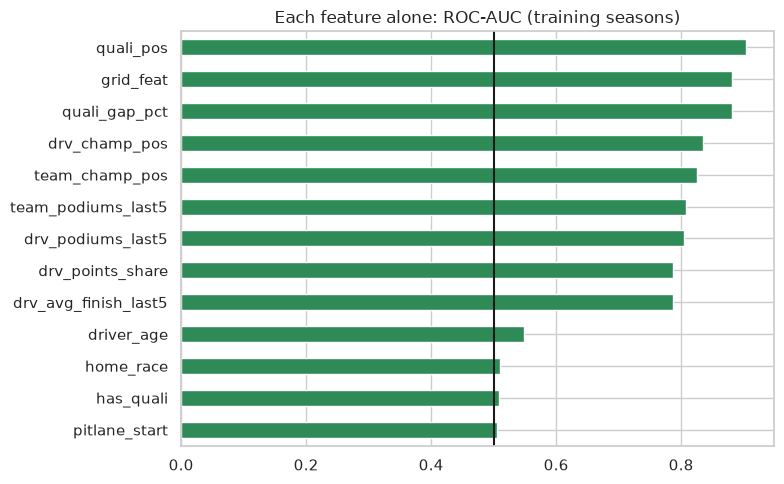

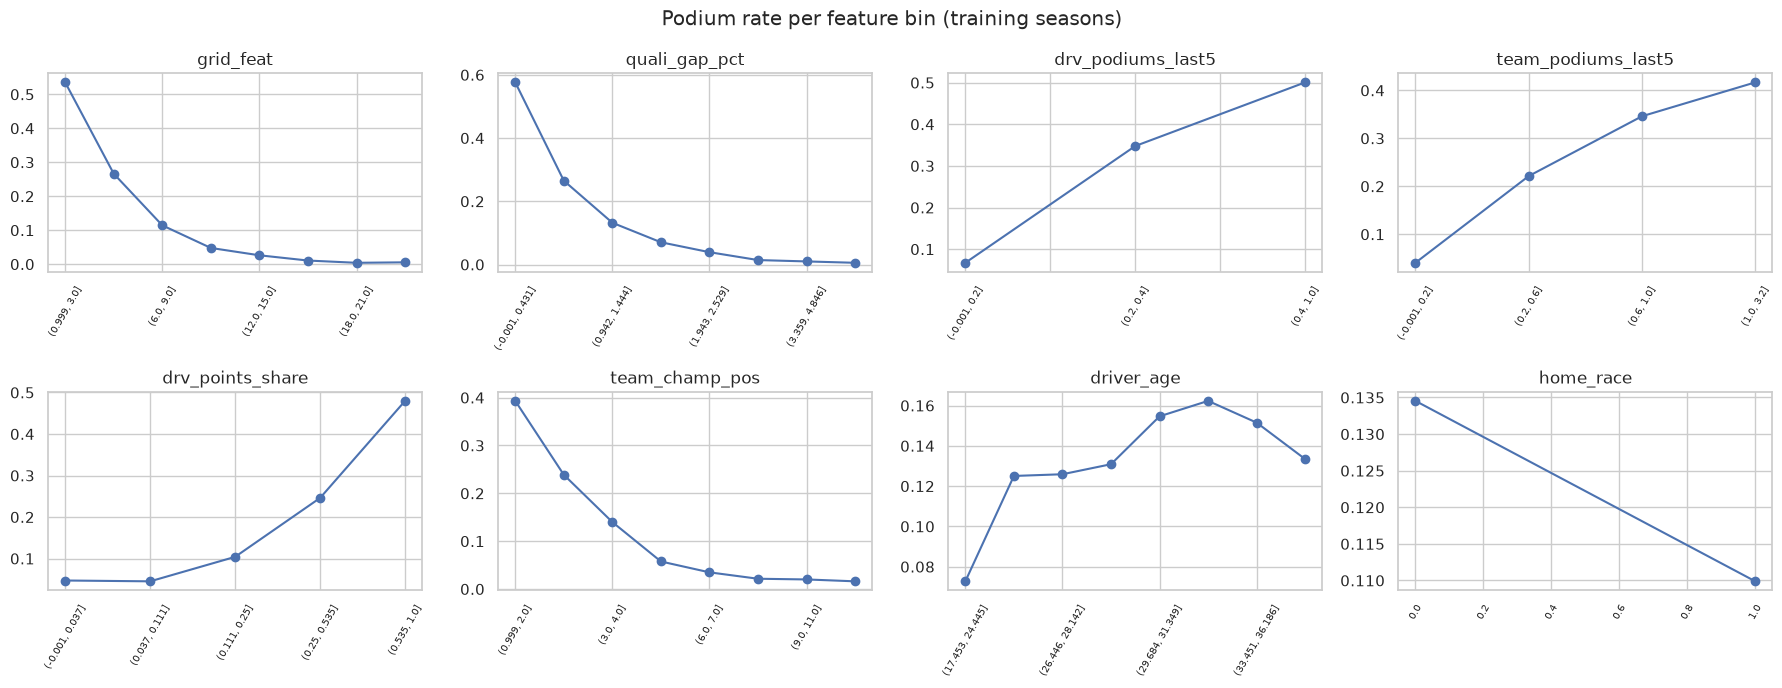

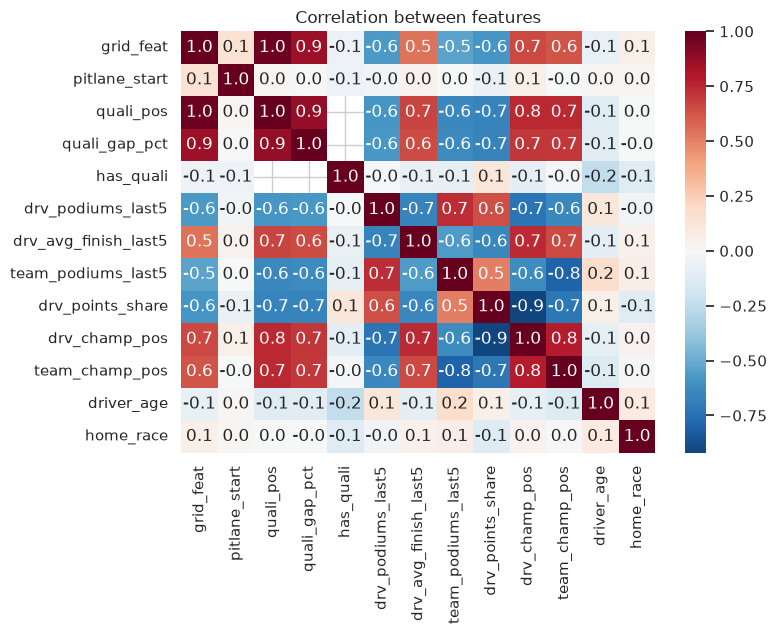

In [65]:
train_part = data[data.year <= 2017]
def single_auc(col):
    x, y = train_part[col], train_part.podium
    ok = x.notna(); a = roc_auc_score(y[ok], x[ok]); return max(a, 1 - a)
auc_table = pd.Series({f: single_auc(f) for f in FEATURES}).sort_values()
auc_table.plot.barh(figsize=(8, 5), color="seagreen"); plt.axvline(0.5, c="k")
plt.title("Each feature alone: ROC-AUC (training seasons)"); plt.tight_layout(); plt.show()

fig, axes = plt.subplots(2, 4, figsize=(18, 7)); axes = axes.ravel()
for ax, f in zip(axes, ["grid_feat", "quali_gap_pct", "drv_podiums_last5", "team_podiums_last5",
                        "drv_points_share", "team_champ_pos", "driver_age", "home_race"]):
    bins = train_part[f] if train_part[f].nunique() <= 6 else pd.qcut(train_part[f], 8, duplicates="drop")
    train_part.groupby(bins, observed=True).podium.mean().plot(ax=ax, marker="o")
    ax.set_title(f); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=60, labelsize=7)
plt.suptitle("Podium rate per feature bin (training seasons)"); plt.tight_layout(); plt.show()

plt.figure(figsize=(8, 6.5))
sns.heatmap(train_part[FEATURES].corr(method="spearman"), cmap="RdBu_r", center=0, annot=True, fmt=".1f")
plt.title("Correlation between features"); plt.tight_layout(); plt.show()

**Why each feature is kept:**
* **grid / qualifying:** among the strongest signals in the chart above (`grid_feat` has complete coverage; the qualifying features are missing for old seasons, so their AUC is computed on the rows that have them). The podium rate drops very fast with worse grid or a bigger gap to pole.
* **form & standings:** strong (see the AUC chart). They tell us *how good the car is*: a fast car that starts P8 after a penalty still has a chance.
* **context:** weak. `driver_age` peaks in the early 30s; `home_race` shows almost no effect (matches Q2). We keep them because they are cheap and the ablation will test them.
* **`has_quali`:** carries no information about the race itself; it only tells the model whether the qualifying features are real or imputed.
* **Correlations:** grid and qualifying position are strongly correlated (most drivers start where they qualified). We keep both because penalties make them different, and our ablation measures what each adds.

**Leakage check:** to show what leakage looks like, we compute the AUC of `points` from the **same** race — it is almost perfect. That is exactly why it is not allowed.

In [66]:
print("AUC of 'points' of the same race (forbidden):", round(single_auc("points"), 3))
print("AUC of 'grid' (allowed):", round(single_auc("grid_feat"), 3))

AUC of 'points' of the same race (forbidden): 0.975
AUC of 'grid' (allowed): 0.881


## 7. Train / validation / test split

We split by **season** (time), not randomly:

| Split | Seasons | Used for |
|---|---|---|
| Train | 1950–2017 | fitting the models (qualifying features missing before 2003, flagged by `has_quali`) |
| Validation | 2018–2021 | choosing hyperparameters and the decision threshold |
| Test | 2022–2024 | final evaluation, reported only (never used for selection) |

**Why by time?** The model will be used to predict *future* races, so we must test it on races that come after the training data. A random split would put races from the same season (or even the same race) in train and test, which makes the score look better than it really is. 2022 also starts new car rules, so the test set is a fair "unseen future" check.

In [67]:
train = data[data.year <= 2017]; val = data[(data.year >= 2018) & (data.year <= 2021)]; test = data[data.year >= 2022]
X_train, y_train = train[FEATURES], train.podium.values
X_val, y_val = val[FEATURES], val.podium.values
X_test, y_test = test[FEATURES], test.podium.values
pd.DataFrame({"rows": [len(train), len(val), len(test)], "podium rate": [y_train.mean(), y_val.mean(), y_test.mean()]},
             index=["train", "validation", "test"]).round(3)

,rows,podium rate
train,22326,0.132
validation,1620,0.150
test,1359,0.150


## 8. Pre-processing

1. **Imputation:** fill missing values with the **median** of the training data (median is robust to skewed features).
2. **Scaling:** `StandardScaler` → each feature has mean 0 and standard deviation 1. Logistic regression and the neural network need this; the random forest does not.

Both are **fit on the training set only**, then applied to validation and test.

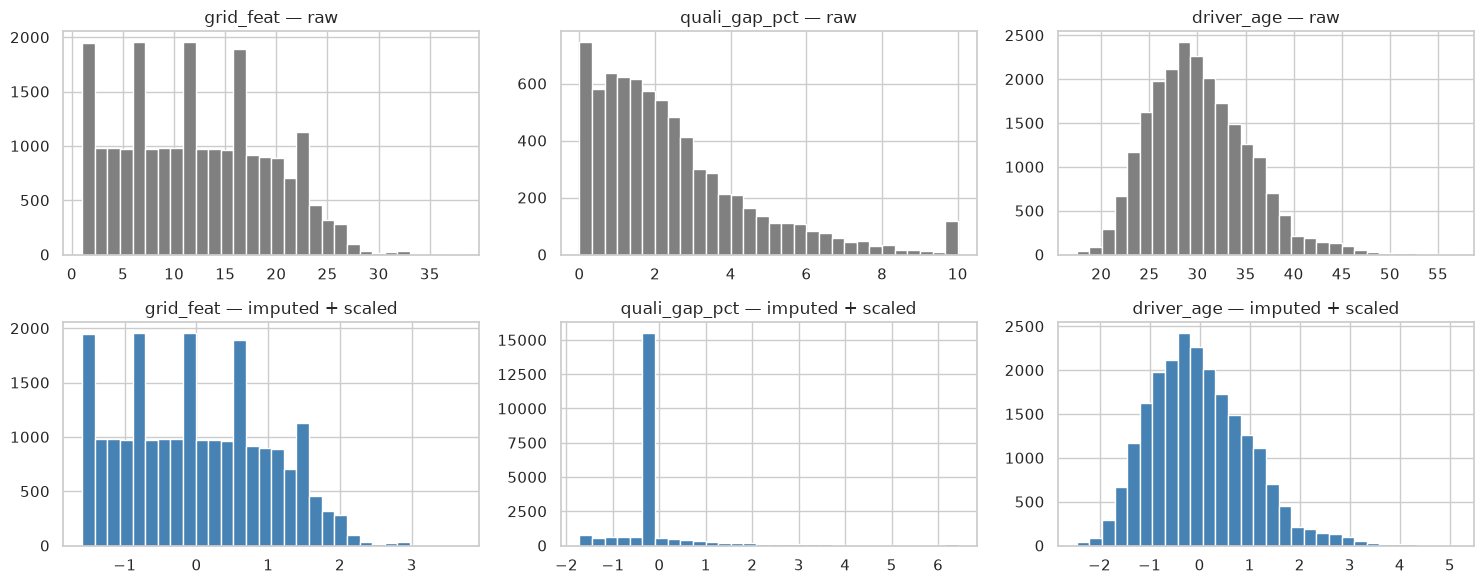

,raw mean,raw std,after mean,after std
grid_feat,12.19,7.02,-0.0,1.0
pitlane_start,0.01,0.10,-0.0,1.0
quali_pos,11.47,6.42,0.0,1.0
quali_gap_pct,2.46,2.09,0.0,1.0
has_quali,0.34,0.47,0.0,1.0
drv_podiums_last5,0.13,0.23,0.0,1.0
drv_avg_finish_last5,11.99,4.54,0.0,1.0
team_podiums_last5,0.34,0.51,0.0,1.0
drv_points_share,0.18,0.28,0.0,1.0
drv_champ_pos,13.24,9.31,0.0,1.0


In [68]:
imputer = SimpleImputer(strategy="median").fit(X_train)
scaler = StandardScaler().fit(imputer.transform(X_train))
def prep(X, scale=True):
    Z = imputer.transform(X)
    return scaler.transform(Z) if scale else Z

Xtr_imp, Xva_imp, Xte_imp = prep(X_train, False), prep(X_val, False), prep(X_test, False)
Xtr_sc, Xva_sc, Xte_sc = prep(X_train), prep(X_val), prep(X_test)

fig, ax = plt.subplots(2, 3, figsize=(15, 6))
for j, f in enumerate(["grid_feat", "quali_gap_pct", "driver_age"]):
    i = FEATURES.index(f)
    ax[0, j].hist(X_train[f].dropna(), bins=30, color="grey"); ax[0, j].set_title(f"{f} — raw")
    ax[1, j].hist(Xtr_sc[:, i], bins=30, color="steelblue"); ax[1, j].set_title(f"{f} — imputed + scaled")
plt.tight_layout(); plt.show()
pd.DataFrame({"raw mean": X_train.mean(), "raw std": X_train.std(), "after mean": Xtr_sc.mean(0), "after std": Xtr_sc.std(0)},
             index=FEATURES).round(2)

**Effect:** the shape of each distribution stays the same; only the scale changes (all features now have mean 0, std 1 and no missing values). Imputation adds a small spike at the median for features that had missing values.

### 8.1 Pre-processing-order experiments
We keep the model fixed (logistic regression) and change only the **order** of pre-processing steps:
* **Experiment 1 — fit the scaler/imputer before vs after splitting.** "Before" = fit on *all* data, including test (a common mistake: test information leaks into training).
* **Experiment 2 — impute then scale vs scale then impute.**

In [69]:
def lr_score(Xtr, Xva, Xte):
    m = LogisticRegression(max_iter=2000).fit(Xtr, y_train)
    return {"val PR-AUC": average_precision_score(y_val, m.predict_proba(Xva)[:, 1]),
            "test PR-AUC": average_precision_score(y_test, m.predict_proba(Xte)[:, 1])}

rows = {}
# correct: fit on train only (already done above)
rows["E1: fit on train only (correct)"] = lr_score(Xtr_sc, Xva_sc, Xte_sc)
# wrong: fit on everything before splitting
all_X = pd.concat([X_train, X_val, X_test])
imp_all = SimpleImputer(strategy="median").fit(all_X); sc_all = StandardScaler().fit(imp_all.transform(all_X))
f_all = lambda X: sc_all.transform(imp_all.transform(X))
rows["E1: fit on ALL data before split (leaky)"] = lr_score(f_all(X_train), f_all(X_val), f_all(X_test))
# order: scale first, then impute
sc_first = StandardScaler().fit(X_train)                     # StandardScaler ignores NaN when fitting
imp_after = SimpleImputer(strategy="median").fit(sc_first.transform(X_train))
f_si = lambda X: imp_after.transform(sc_first.transform(X))
rows["E2: impute -> scale"] = rows["E1: fit on train only (correct)"]
rows["E2: scale -> impute"] = lr_score(f_si(X_train), f_si(X_val), f_si(X_test))
pd.DataFrame(rows).T.round(4)

,val PR-AUC,test PR-AUC
E1: fit on train only (correct),0.7059,0.7102
E1: fit on ALL data before split (leaky),0.7057,0.7095
E2: impute -> scale,0.7059,0.7102
E2: scale -> impute,0.7059,0.7096


**Result** (PR-AUC differs only in the 4th decimal):
* **Experiment 1:** the scores are almost the same, because the medians and means barely change with more data. But the "fit on all data" version is still **wrong**: it uses test-set statistics during training, which is impossible in real use. We keep "fit on train only".
* **Experiment 2:** both orders give nearly identical results. We keep the standard order **impute → scale**, so the scaler sees complete data.

### 8.2 Experiment — training period: all seasons vs 2003 onwards
The qualifying features exist only from 2003, so a tempting shortcut is to drop the older seasons. We compare it with keeping them. Same validation and test seasons, same features (including `has_quali`), same preprocessing recipe (imputer and scaler fit on the respective training rows only); only the **training rows** change. The metric is PR-AUC (see 9.5).


In [70]:
# 8.2 Training period experiment: all seasons (1950-2017) vs 2003-2017 only
def period_scores(mask):
    Xt, yt = X_train[mask], y_train[mask]
    imp = SimpleImputer(strategy="median").fit(Xt)
    sc = StandardScaler().fit(imp.transform(Xt))
    Z = lambda X: imp.transform(X)
    lr = LogisticRegression(max_iter=2000).fit(sc.transform(Z(Xt)), yt)
    rf_ = RandomForestClassifier(n_estimators=300, max_depth=5, min_samples_split=40, min_samples_leaf=20,
                                 max_features=0.5, random_state=SEED, n_jobs=-1).fit(Z(Xt), yt)
    out = {"training rows": int(mask.sum())}
    for name, model, tf in [("LR", lr, lambda X: sc.transform(Z(X))), ("RF", rf_, Z)]:
        out[f"{name} val PR-AUC"] = average_precision_score(y_val, model.predict_proba(tf(X_val))[:, 1])
        out[f"{name} test PR-AUC"] = average_precision_score(y_test, model.predict_proba(tf(X_test))[:, 1])
    return out

in_2003 = (train.year >= 2003).values
period_table = pd.DataFrame({"all seasons (1950-2017)": period_scores(np.ones(len(train), bool)),
                             "2003-2017 only": period_scores(in_2003)}).T
period_table.round(4)


,training rows,LR val PR-AUC,LR test PR-AUC,RF val PR-AUC,RF test PR-AUC
all seasons (1950-2017),22326.0,0.7059,0.7102,0.7254,0.7079
2003-2017 only,5987.0,0.7003,0.7015,0.7293,0.7130


**Result of this run (PR-AUC):**

| training rows | LR val | LR test | RF val | RF test |
|---|---|---|---|---|
| all seasons (22,326) | 0.706 | 0.710 | 0.725 | 0.708 |
| 2003–2017 only (5,987) | 0.700 | 0.702 | 0.729 | 0.713 |

Keeping the older seasons helps the logistic regression slightly and costs the random forest about 0.004 PR-AUC, which is within noise. So discarding ~75 % of the training rows buys nothing, and **we keep all seasons**, consistent with the instructor's guidance. The qualifying features are missing for old seasons and are flagged by `has_quali`. Caveat: the table comes from one run; re-check after a full re-run. Also note `grid = 0` is rare but more frequent in the 1960s (≈ 6 %), where it can mean a missing slot rather than a pit-lane start.


## 9. Predictive models

We train **four models** on the **same rows and features** (`FEATURES`, train/validation/test from Section 7), so their scores are directly comparable.

| # | Model | Type | Role |
|---|---|---|---|
| 9.1 | Logistic regression | statistical | **baseline** |
| 9.2 | Random forest | statistical (tree ensemble) | comparison |
| 9.3 | Gradient boosting | statistical (boosted trees) | comparison |
| 9.4 | Shallow neural network (1–2 hidden layers) | neural network | comparison |

**Rules for every model**
- Inputs come from the preprocessing in Section 8: imputation and scaling are fit on train only. The random forest and gradient boosting use the imputed, unscaled features.
- Hyperparameters and the decision threshold are chosen on **train and validation** only.
- The **test set never influences a choice**: hyperparameters, thresholds and the reference model are selected on validation only. Test scores are computed next to the others but are only reported (9.5).
- Each model reports **ROC-AUC, PR-AUC and F1** on validation and on test.


### 9.1 Logistic regression (baseline)

**How it works.** Logistic regression computes a weighted sum of the standardised features, `z = b + w1·x1 + w2·x2 + …`, and turns it into a probability with the sigmoid, `P(podium) = 1 / (1 + e^-z)`. The weights are learned by minimising the log-loss on the training seasons, with a mild L2 penalty (scikit-learn default, `C = 1`). Each weight says how much the log-odds of a podium change when that feature rises by one standard deviation, all other features held fixed. We use it as the **baseline**: it is the simplest reasonable model, fast, and easy to read, so the other models must beat it to justify their complexity.

**Decision threshold.** The model outputs a probability. To get podium / not-podium we need a cut-off. Only about 14 % of rows are podiums, so 0.5 is too high. We pick the threshold that maximises F1 on the **validation** seasons only, and apply it unchanged to the test seasons.

**Limitations.**
* **Linear in the features.** The EDA (4.3, 6.5) showed the podium rate falls *non-linearly* with grid position, which a straight-line model can only approximate. It also cannot learn interactions (e.g. "good car AND front row").
* **Correlated features.** `grid_feat` and `quali_pos` correlate at about 0.96, and `drv_champ_pos` and `drv_points_share` at about -0.83. This makes the individual coefficients unstable, so they should not be read as a ranking of importance (use the permutation importance and SHAP in Section 11 for that).
* **Era sensitivity.** One set of weights is used for 1950-2024, although the competitive order and rules change between eras.
* **Imbalanced classes.** With few positives the probabilities are good for ranking (ROC-AUC, PR-AUC), but the F1 depends strongly on the chosen threshold.
* **Coefficients are associations, not causes.**

**What the cell reports:** train, validation and test scores for ROC-AUC, PR-AUC, F1, precision, recall and accuracy; a confusion matrix; ROC and precision-recall curves; and the coefficients.


converged in 22 iterations
Decision threshold (validation F1-optimal): 0.346


,train,validation,test
ROC-AUC,0.8965,0.9304,0.9337
PR-AUC,0.5612,0.7059,0.7102
F1,0.5634,0.7229,0.6816
Precision,0.5369,0.6523,0.6281
Recall,0.5926,0.8107,0.7451
Accuracy,0.8787,0.9068,0.8955


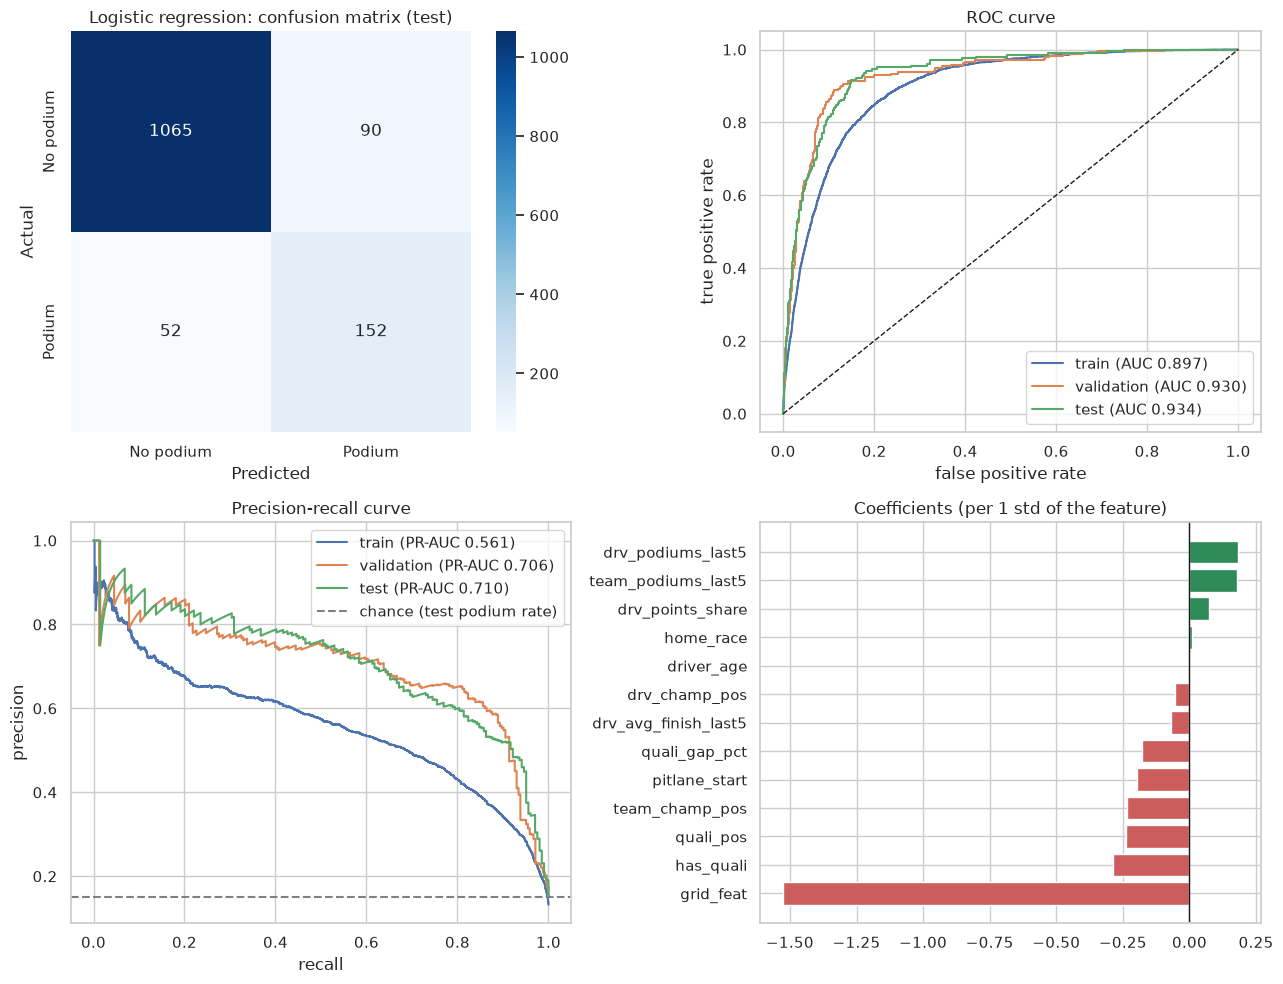

Brier score (validation): 0.0667 | mean predicted 0.157 vs actual podium rate 0.150


In [71]:
# 9.1 Logistic regression (baseline)
results = globals().get("results", {})

from sklearn.metrics import (accuracy_score, precision_score, recall_score, confusion_matrix,
                             roc_curve, brier_score_loss)

# 1) Fit on training data only
logisticReg = LogisticRegression(max_iter=1000, random_state=SEED)
logisticReg.fit(Xtr_sc, y_train)
print(f"converged in {logisticReg.n_iter_[0]} iterations")

p_train_lr = logisticReg.predict_proba(Xtr_sc)[:, 1]
p_val_lr = logisticReg.predict_proba(Xva_sc)[:, 1]
p_test_lr = logisticReg.predict_proba(Xte_sc)[:, 1]

# 2) Decision threshold: maximise F1 on VALIDATION only
prec_lr, rec_lr, thr_lr = precision_recall_curve(y_val, p_val_lr)
f1_curve_lr = 2 * prec_lr[:-1] * rec_lr[:-1] / np.maximum(prec_lr[:-1] + rec_lr[:-1], 1e-12)
threshold_lr = thr_lr[f1_curve_lr.argmax()]

# 3) All metrics on train, validation and test (same threshold everywhere)
def lr_metrics(y, p, threshold):
    pred = p >= threshold
    return {"ROC-AUC": roc_auc_score(y, p), "PR-AUC": average_precision_score(y, p),
            "F1": f1_score(y, pred), "Precision": precision_score(y, pred),
            "Recall": recall_score(y, pred), "Accuracy": accuracy_score(y, pred)}

results["Logistic Regression"] = {"train": lr_metrics(y_train, p_train_lr, threshold_lr),
                                  "validation": lr_metrics(y_val, p_val_lr, threshold_lr),
                                  "test": lr_metrics(y_test, p_test_lr, threshold_lr)}
print(f"Decision threshold (validation F1-optimal): {threshold_lr:.3f}")
display(pd.DataFrame(results["Logistic Regression"]).round(4))

# 4) Plots: confusion matrix (test), ROC, precision-recall, coefficients
y_pred_test_lr = (p_test_lr >= threshold_lr).astype(int)
fig, ax = plt.subplots(2, 2, figsize=(13, 10))
sns.heatmap(confusion_matrix(y_test, y_pred_test_lr), annot=True, fmt="d", cmap="Blues", ax=ax[0, 0],
            xticklabels=["No podium", "Podium"], yticklabels=["No podium", "Podium"])
ax[0, 0].set_xlabel("Predicted"); ax[0, 0].set_ylabel("Actual"); ax[0, 0].set_title("Logistic regression: confusion matrix (test)")

for name, y, p in [("train", y_train, p_train_lr), ("validation", y_val, p_val_lr), ("test", y_test, p_test_lr)]:
    fpr, tpr, _ = roc_curve(y, p)
    ax[0, 1].plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(y, p):.3f})")
    pr, rc, _ = precision_recall_curve(y, p)
    ax[1, 0].plot(rc, pr, label=f"{name} (PR-AUC {average_precision_score(y, p):.3f})")
ax[0, 1].plot([0, 1], [0, 1], "k--", lw=1); ax[0, 1].set_xlabel("false positive rate"); ax[0, 1].set_ylabel("true positive rate")
ax[0, 1].set_title("ROC curve"); ax[0, 1].legend()
ax[1, 0].axhline(y_test.mean(), ls="--", color="grey", label="chance (test podium rate)")
ax[1, 0].set_xlabel("recall"); ax[1, 0].set_ylabel("precision"); ax[1, 0].set_title("Precision-recall curve"); ax[1, 0].legend()

coef = pd.Series(logisticReg.coef_[0], index=FEATURES).sort_values()
ax[1, 1].barh(coef.index, coef.values, color=np.where(coef.values < 0, "indianred", "seagreen"))
ax[1, 1].axvline(0, c="k", lw=1); ax[1, 1].set_title("Coefficients (per 1 std of the feature)")
plt.tight_layout(); plt.show()

print(f"Brier score (validation): {brier_score_loss(y_val, p_val_lr):.4f} | "
      f"mean predicted {p_val_lr.mean():.3f} vs actual podium rate {y_val.mean():.3f}")


### 9.2 Random forest

**How it works.** Random forest averages predictions from many decision trees to estimate podium probability. It can learn non-linear relationships and feature interactions. We use the **imputed, unscaled** features from Section 8.

**Model selection.** We compare 12 configurations with 300 trees, choosing the highest **validation PR-AUC (average precision)**. The selected settings are printed under the search table.

**Overfitting check.** The search table lists the train-minus-validation PR-AUC gap for every configuration. Deeper configurations improve training PR-AUC but reduce validation PR-AUC, suggesting overfitting relative to the shallower forest. The selected model performs better on validation than training (gap = -0.1368 in the saved run); differences between racing eras may contribute, so the gap alone does not establish whether overfitting is absent.

**Decision threshold.** We maximise F1 on the **validation set**, (the selected value is printed with the metrics). Hyperparameters and the threshold are fixed before final test evaluation.

**Limitations.**

* **Interpretability:** harder to explain than logistic regression; feature importance does not establish causation.
* **Correlated features:** grid and qualifying position contain overlapping information.
* **Era sensitivity:** changes in F1 rules and performance may affect future predictions.
* **Independent predictions:** the model does not enforce exactly three podium finishers per race.

**What the cells report:** the hyperparameter search; training, validation and test metrics; validation and test confusion matrices; ROC and precision-recall curves; and feature importance.


In [72]:
# 9.2 Random Forest — Hyperparameter tuning
results = globals().get("results", {})

rf_profiles = [
    (5, 40, 20),
    (8, 20, 10),
    (12, 10, 5)
]

rf_runs = {}
rf_scores = []

for depth, split, leaf in rf_profiles:
    for features in [0.5, "sqrt"]:
        for weight in [None, "balanced"]:

            model = RandomForestClassifier(
                n_estimators=300,
                max_depth=depth,
                min_samples_split=split,
                min_samples_leaf=leaf,
                max_features=features,
                class_weight=weight,
                random_state=SEED,
                n_jobs=-1
            )

            model.fit(Xtr_imp, y_train)

            p_train = model.predict_proba(Xtr_imp)[:, 1]
            p_val = model.predict_proba(Xva_imp)[:, 1]

            train_ap = average_precision_score(y_train, p_train)
            val_ap = average_precision_score(y_val, p_val)

            key = (depth, split, leaf, features, weight)
            rf_runs[key] = model

            rf_scores.append({
                "max_depth": depth,
                "min_samples_split": split,
                "min_samples_leaf": leaf,
                "max_features": features,
                "class_weight": str(weight),
                "Train PR-AUC": train_ap,
                "Val PR-AUC": val_ap,
                "Gap": train_ap - val_ap
            })

rf_search = pd.DataFrame(rf_scores).sort_values(
    "Val PR-AUC", ascending=False
).reset_index(drop=True)

display(rf_search.round(4))

best = rf_search.iloc[0]
best_key = (
    int(best["max_depth"]),
    int(best["min_samples_split"]),
    int(best["min_samples_leaf"]),
    best["max_features"],
    None if best["class_weight"] == "None" else "balanced"
)

rf = rf_runs[best_key]

print("Best Random Forest:", best_key)
print(f"Validation PR-AUC: {best['Val PR-AUC']:.4f}")

,max_depth,min_samples_split,min_samples_leaf,max_features,class_weight,Train PR-AUC,Val PR-AUC,Gap
0,5,40,20,0.5,None,0.5886,0.7254,-0.1368
1,5,40,20,0.5,balanced,0.5801,0.7198,-0.1396
2,8,20,10,0.5,None,0.6574,0.7188,-0.0614
3,8,20,10,0.5,balanced,0.6411,0.7187,-0.0777
4,5,40,20,sqrt,None,0.5803,0.7171,-0.1368
5,8,20,10,sqrt,balanced,0.6248,0.7166,-0.0919
6,8,20,10,sqrt,None,0.6358,0.7166,-0.0808
7,5,40,20,sqrt,balanced,0.5733,0.7150,-0.1417
8,12,10,5,0.5,balanced,0.8025,0.7128,0.0896
9,12,10,5,sqrt,balanced,0.7562,0.7123,0.0439


Best Random Forest: (5, 40, 20, 0.5, None)
Validation PR-AUC: 0.7254


In [73]:
# 9.2 Random Forest — Threshold Selection and Evaluation

p_train_rf = rf.predict_proba(Xtr_imp)[:, 1]
p_val_rf = rf.predict_proba(Xva_imp)[:, 1]

# Select the threshold maximizing validation F1
prec_rf, rec_rf, thr_rf = precision_recall_curve(y_val, p_val_rf)

f1_curve_rf = (
    2 * prec_rf[:-1] * rec_rf[:-1] /
    np.maximum(prec_rf[:-1] + rec_rf[:-1], 1e-12)
)

threshold_rf = thr_rf[f1_curve_rf.argmax()]

# Calculate evaluation metrics
def rf_metrics(y, p):
    pred = (p >= threshold_rf).astype(int)

    return {
        "ROC-AUC": roc_auc_score(y, p),
        "PR-AUC": average_precision_score(y, p),
        "F1": f1_score(y, pred),
        "Precision": precision_score(y, pred, zero_division=0),
        "Recall": recall_score(y, pred, zero_division=0),
        "Accuracy": accuracy_score(y, pred)
    }

p_test_rf = rf.predict_proba(Xte_imp)[:, 1]
results["Random Forest"] = {
    "train": rf_metrics(y_train, p_train_rf),
    "validation": rf_metrics(y_val, p_val_rf),
    "test": rf_metrics(y_test, p_test_rf)
}

print(f"Selected threshold: {threshold_rf:.3f}")
display(pd.DataFrame(results["Random Forest"]).round(4))
rf_r = results["Random Forest"]
print(f"PR-AUC gap (train - validation): {rf_r['train']['PR-AUC'] - rf_r['validation']['PR-AUC']:.4f}")

Selected threshold: 0.449


,train,validation,test
ROC-AUC,0.9036,0.9399,0.9408
PR-AUC,0.5886,0.7254,0.7079
F1,0.5291,0.7195,0.6667
Precision,0.6060,0.7108,0.7049
Recall,0.4695,0.7284,0.6324
Accuracy,0.8896,0.9148,0.9051


PR-AUC gap (train - validation): -0.1368


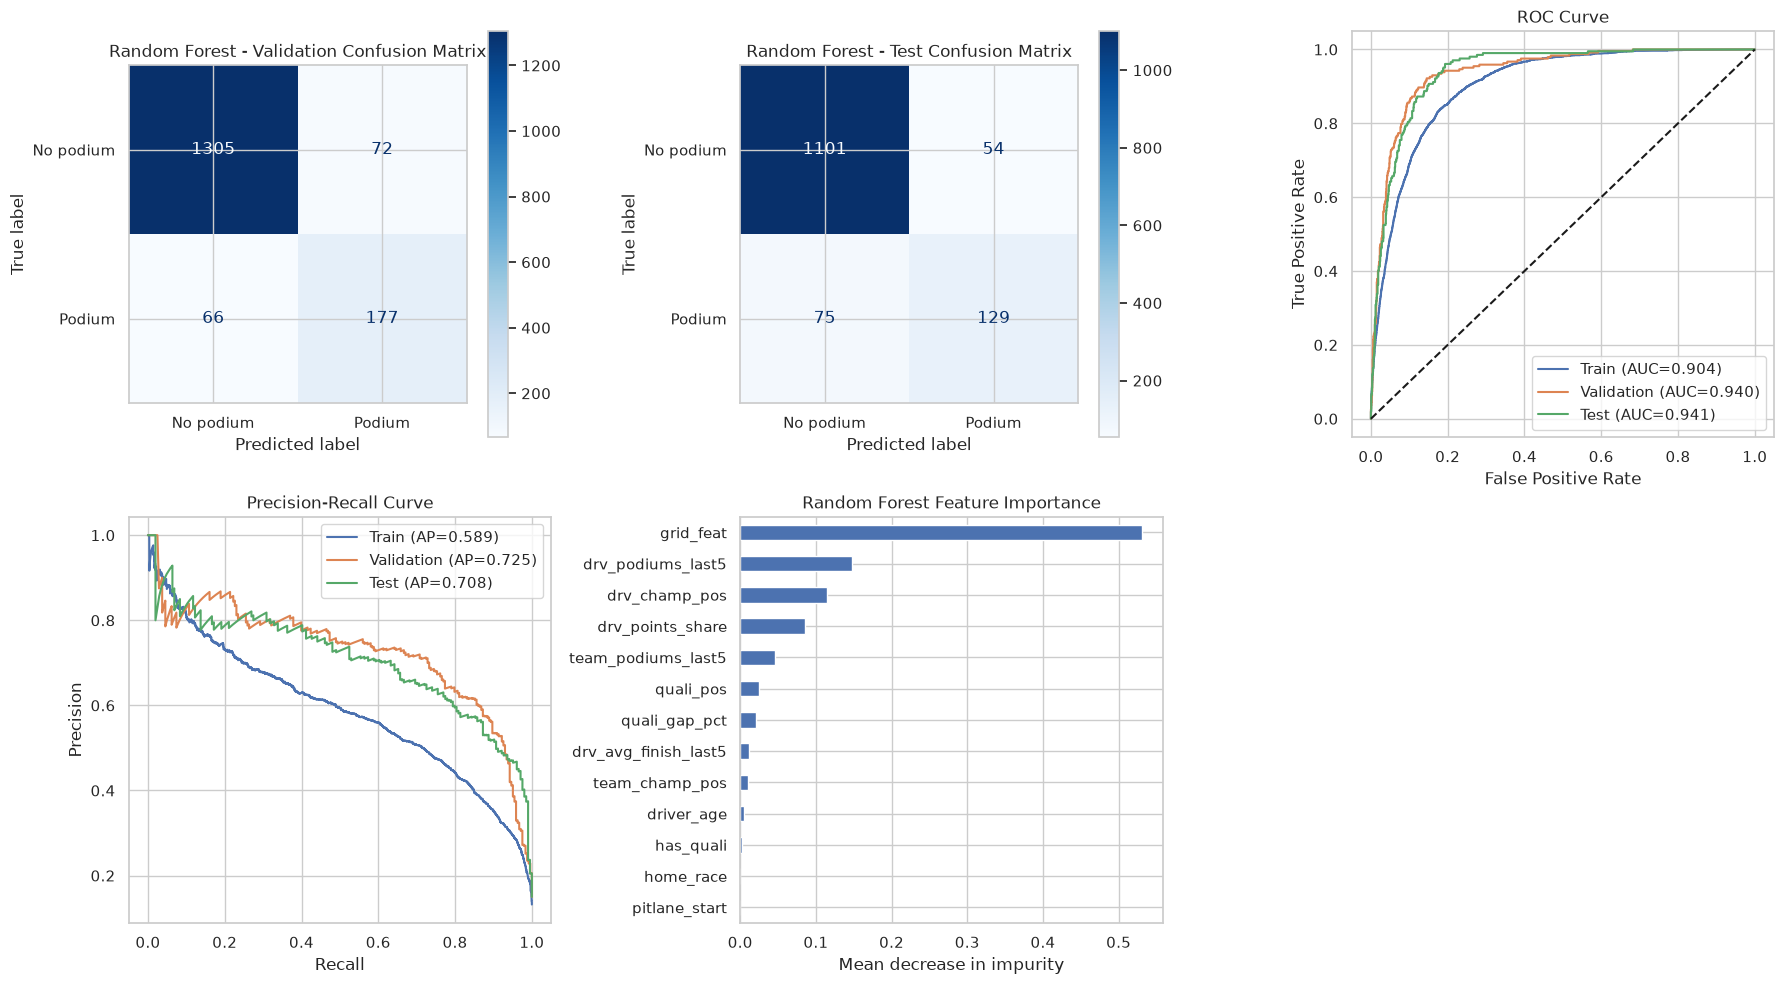

In [74]:
# 9.2 Random Forest — Visualizations

y_pred_rf = (p_val_rf >= threshold_rf).astype(int)

fig, ax = plt.subplots(2, 3, figsize=(18, 10))

# 1. Confusion Matrix (Validation)
ConfusionMatrixDisplay.from_predictions(
    y_val, y_pred_rf,
    display_labels=["No podium", "Podium"],
    cmap="Blues",
    ax=ax[0, 0]
)
ax[0, 0].set_title("Random Forest - Validation Confusion Matrix")
ConfusionMatrixDisplay.from_predictions(
    y_test, (p_test_rf >= threshold_rf).astype(int),
    display_labels=["No podium", "Podium"], cmap="Blues", ax=ax[0, 1]
)
ax[0, 1].set_title("Random Forest - Test Confusion Matrix")

# 2. ROC Curve
for name, y, p in [
    ("Train", y_train, p_train_rf),
    ("Validation", y_val, p_val_rf),
    ("Test", y_test, p_test_rf)
]:
    fpr, tpr, _ = roc_curve(y, p)
    ax[0, 2].plot(
        fpr, tpr,
        label=f"{name} (AUC={roc_auc_score(y, p):.3f})"
    )

ax[0, 2].plot([0, 1], [0, 1], "k--")
ax[0, 2].set_title("ROC Curve")
ax[0, 2].set_xlabel("False Positive Rate")
ax[0, 2].set_ylabel("True Positive Rate")
ax[0, 2].legend()

# 3. Precision-Recall Curve
for name, y, p in [
    ("Train", y_train, p_train_rf),
    ("Validation", y_val, p_val_rf),
    ("Test", y_test, p_test_rf)
]:
    precision, recall, _ = precision_recall_curve(y, p)
    ax[1, 0].plot(
        recall, precision,
        label=f"{name} (AP={average_precision_score(y, p):.3f})"
    )

ax[1, 0].set_title("Precision-Recall Curve")
ax[1, 0].set_xlabel("Recall")
ax[1, 0].set_ylabel("Precision")
ax[1, 0].legend()

# 4. Feature Importance
importance = pd.Series(
    rf.feature_importances_,
    index=FEATURES
).sort_values()

importance.plot.barh(ax=ax[1, 1])
ax[1, 1].set_title("Random Forest Feature Importance")
ax[1, 1].set_xlabel("Mean decrease in impurity")
ax[1, 2].axis("off")

plt.tight_layout()
plt.show()

### 9.3 Gradient boosting

**How it works.** Trees are built one after another, and each new small tree corrects the mistakes of the trees before it (boosting). This differs from a random forest, where independent trees are averaged. We use the **imputed, unscaled** features from Section 8.

**Model selection.** We compare three setups on **validation PR-AUC**, all with subsampling (`subsample=0.8`) and `min_samples_leaf=20` to limit overfitting: a shallow/slow one (depth 2, learning rate 0.03), a medium one (depth 3, learning rate 0.05) and a deeper one (depth 4, learning rate 0.05, fewer trees). The train-minus-validation gap is shown for each. The decision threshold maximises F1 on validation only.

**Limitations.**
* More hyperparameters to tune than the random forest or logistic regression, and it overfits easily with many or deep trees (see the gap column).
* Harder to interpret than logistic regression; feature importance is not causation.
* Correlated features (grid and qualifying) share credit.
* Predictions are independent per driver, so the model does not enforce exactly three podium finishers per race.
* Era sensitivity: one model is fitted for 1950-2017 and applied to later regulation eras.


In [75]:
# 9.3 Gradient boosting: compare three setups on validation, choose threshold on validation F1, score train / validation / test
from sklearn.ensemble import GradientBoostingClassifier
results = globals().get("results", {})

gb_configs = {
    "shallow/slow (depth 2, lr 0.03)": dict(max_depth=2, learning_rate=0.03, n_estimators=300),
    "medium (depth 3, lr 0.05)": dict(max_depth=3, learning_rate=0.05, n_estimators=300),
    "deeper (depth 4, lr 0.05)": dict(max_depth=4, learning_rate=0.05, n_estimators=200),
}
gb_runs, gb_rows = {}, []
for gb_label, params in gb_configs.items():
    m = GradientBoostingClassifier(subsample=0.8, min_samples_leaf=20, random_state=SEED, **params).fit(Xtr_imp, y_train)
    ap_tr = average_precision_score(y_train, m.predict_proba(Xtr_imp)[:, 1])
    ap_va = average_precision_score(y_val, m.predict_proba(Xva_imp)[:, 1])
    gb_runs[gb_label] = m
    gb_rows.append({"setup": gb_label, "Train PR-AUC": ap_tr, "Val PR-AUC": ap_va, "Gap": ap_tr - ap_va})
gb_search = pd.DataFrame(gb_rows).set_index("setup").sort_values("Val PR-AUC", ascending=False)
display(gb_search.round(4))

gb_choice = gb_search.index[0]
gb = gb_runs[gb_choice]
print("Chosen setup (best validation PR-AUC):", gb_choice)

p_train_gb = gb.predict_proba(Xtr_imp)[:, 1]
p_val_gb = gb.predict_proba(Xva_imp)[:, 1]
p_test_gb = gb.predict_proba(Xte_imp)[:, 1]

# threshold with the best F1 on validation only
prec_gb, rec_gb, thr_gb = precision_recall_curve(y_val, p_val_gb)
f1_curve_gb = 2 * prec_gb[:-1] * rec_gb[:-1] / np.maximum(prec_gb[:-1] + rec_gb[:-1], 1e-12)
threshold_gb = thr_gb[f1_curve_gb.argmax()]

def gb_metrics(y, p):
    pred = (p >= threshold_gb).astype(int)
    return {"ROC-AUC": roc_auc_score(y, p), "PR-AUC": average_precision_score(y, p),
            "Precision": precision_score(y, pred, zero_division=0), "Recall": recall_score(y, pred, zero_division=0),
            "F1": f1_score(y, pred), "Accuracy": accuracy_score(y, pred)}

results["Gradient Boosting"] = {"train": gb_metrics(y_train, p_train_gb),
                                "validation": gb_metrics(y_val, p_val_gb),
                                "test": gb_metrics(y_test, p_test_gb)}

print(f"Selected threshold: {threshold_gb:.3f}")
display(pd.DataFrame(results["Gradient Boosting"]).round(4))


,Train PR-AUC,Val PR-AUC,Gap
setup,,,
"shallow/slow (depth 2, lr 0.03)",0.5862,0.7094,-0.1232
"medium (depth 3, lr 0.05)",0.6385,0.7029,-0.0644
"deeper (depth 4, lr 0.05)",0.6567,0.7024,-0.0457


Chosen setup (best validation PR-AUC): shallow/slow (depth 2, lr 0.03)
Selected threshold: 0.418


,train,validation,test
ROC-AUC,0.9034,0.9363,0.9422
PR-AUC,0.5862,0.7094,0.7093
Precision,0.5725,0.6856,0.6881
Recall,0.5373,0.7449,0.6814
F1,0.5543,0.7140,0.6847
Accuracy,0.8859,0.9105,0.9058


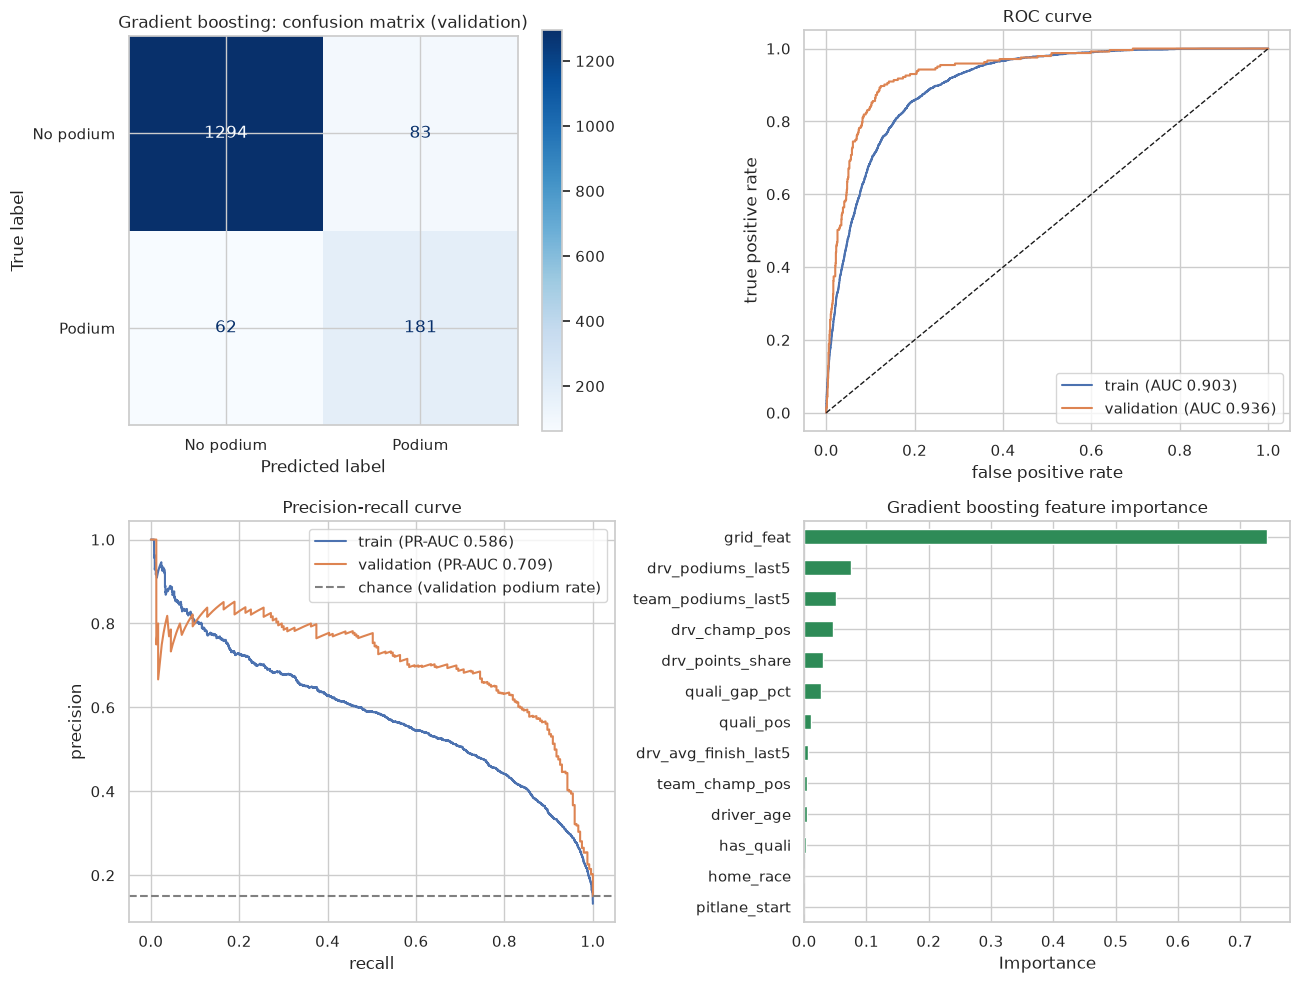

In [76]:
# 9.3 Gradient boosting: validation confusion matrix, ROC, precision-recall and feature importance
fig, ax = plt.subplots(2, 2, figsize=(13, 10))
ConfusionMatrixDisplay.from_predictions(y_val, (p_val_gb >= threshold_gb).astype(int),
                                        display_labels=["No podium", "Podium"], cmap="Blues", ax=ax[0, 0])
ax[0, 0].set_title("Gradient boosting: confusion matrix (validation)")

for name, y, p in [("train", y_train, p_train_gb), ("validation", y_val, p_val_gb)]:
    fpr, tpr, _ = roc_curve(y, p)
    ax[0, 1].plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(y, p):.3f})")
    pr, rc, _ = precision_recall_curve(y, p)
    ax[1, 0].plot(rc, pr, label=f"{name} (PR-AUC {average_precision_score(y, p):.3f})")
ax[0, 1].plot([0, 1], [0, 1], "k--", lw=1); ax[0, 1].set_xlabel("false positive rate"); ax[0, 1].set_ylabel("true positive rate")
ax[0, 1].set_title("ROC curve"); ax[0, 1].legend()
ax[1, 0].axhline(y_val.mean(), ls="--", color="grey", label="chance (validation podium rate)")
ax[1, 0].set_xlabel("recall"); ax[1, 0].set_ylabel("precision"); ax[1, 0].set_title("Precision-recall curve"); ax[1, 0].legend()

pd.Series(gb.feature_importances_, index=FEATURES).sort_values().plot.barh(ax=ax[1, 1], color="seagreen")
ax[1, 1].set_title("Gradient boosting feature importance"); ax[1, 1].set_xlabel("Importance")
plt.tight_layout(); plt.show()


### 9.4 Shallow neural network

A feed-forward network built with Keras `Sequential`, in the same style as the lab. It has one or two hidden layers of ReLU units and a single sigmoid output for the podium probability. It uses the **imputed and scaled** features from Section 8.

**Why these choices**
- **Sigmoid output and binary cross-entropy:** this is a binary problem (podium or not). The lab's softmax output is for its five-class `cut` problem.
- **Adam optimizer and L2 penalty (`kernel_regularizer`):** Adam is the lab's default optimizer. The L2 penalty limits how large the weights can grow, which reduces overfitting on 12 features.
- **Early stopping on validation loss, with `restore_best_weights=True`:** training stops after 15 epochs without improvement, and the best weights are restored. The lab monitors validation accuracy, but accuracy is misleading when only about one row in seven is a podium. We monitor validation loss instead.
- **Validation data passed explicitly:** we pass the time-based validation set from Section 7 with `validation_data`, not the lab's `validation_split`. A random split would mix seasons and break the time-based split.

**Model selection (train and validation only):** we try three architectures (one hidden layer of 16 or 32 units, or two layers of 32 and 16) and two L2 strengths. We keep the combination with the highest **validation PR-AUC**. The decision threshold is the one that maximises validation F1. The test set is scored only at the end.

**Limitations:** with 12 tabular features, a neural network needs more data to beat tree ensembles, and it is harder to interpret than logistic regression. Results also vary with the random seed, so we fix it with `keras.utils.set_random_seed(SEED)`.

In [77]:
# 9.4 Shallow neural network
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers
from tensorflow.keras.callbacks import EarlyStopping
results = globals().get("results", {})

def build_shallow_nn(hidden_units, l2):
    keras.utils.set_random_seed(SEED)
    model = keras.Sequential([
        layers.Input(shape=(Xtr_sc.shape[1],)),
        *[layers.Dense(u, activation="relu", kernel_regularizer=regularizers.l2(l2)) for u in hidden_units],
        layers.Dense(1, activation="sigmoid"),
    ])
    model.compile(optimizer="adam", loss="binary_crossentropy",
                  metrics=[keras.metrics.AUC(curve="PR", name="pr_auc")],
                  steps_per_execution=16)
    return model

from tqdm.auto import tqdm

class GreenBarEveryEpoch(keras.callbacks.Callback):
    """Green progress bar that advances one step per epoch, showing the loss after that epoch."""
    def __init__(self, epochs, desc=""):
        super().__init__()
        self.epochs, self.desc = epochs, desc

    def on_train_begin(self, logs=None):
        self.bar = tqdm(total=self.epochs, colour="green", desc=self.desc, unit="epoch")

    def on_epoch_end(self, epoch, logs=None):
        self.last_epoch = epoch + 1
        self.bar.update(1)
        self.bar.set_postfix(loss=f"{logs['loss']:.4f}", val_loss=f"{logs['val_loss']:.4f}")

    def on_train_end(self, logs=None):
        # early stopping can end training before `epochs`, so shrink the bar to the epochs actually run
        self.bar.total = self.last_epoch
        self.bar.refresh()
        self.bar.close()

def fit_nn(hidden_units, l2):
    model = build_shallow_nn(hidden_units, l2)
    callbacks = [EarlyStopping(monitor="val_loss", patience=15, restore_best_weights=True),
                 GreenBarEveryEpoch(epochs=200, desc=f"NN {hidden_units}, alpha={l2}")]
    hist = model.fit(Xtr_sc, y_train, validation_data=(Xva_sc, y_val),
                     epochs=200, batch_size=32, verbose=0, callbacks=callbacks)
    return model, hist

architectures = {"1 layer (16)": (16,), "1 layer (32)": (32,), "2 layers (32, 16)": (32, 16)}
alphas = [1e-4, 1e-2]

# 1) choose architecture and L2 strength on validation PR-AUC
nn_runs = {}
for (arch_name, arch), alpha in [(a, al) for a in architectures.items() for al in alphas]:
    model, hist = fit_nn(arch, alpha)
    nn_runs[(arch_name, alpha)] = {"model": model, "history": hist}

search_table = pd.DataFrame({
    key: {"val PR-AUC": average_precision_score(y_val, run["model"].predict(Xva_sc, verbose=0).ravel()),
          "epochs trained": len(run["history"].history["loss"])}
    for key, run in nn_runs.items()
}).T.rename_axis(["architecture", "alpha"]).sort_values("val PR-AUC", ascending=False)
display(search_table.round(4))

best_arch, best_alpha = search_table.index[0]
nn = nn_runs[(best_arch, best_alpha)]["model"]
nn_hist = nn_runs[(best_arch, best_alpha)]["history"]

# 2) decision threshold: maximise F1 on validation only
p_val = nn.predict(Xva_sc, verbose=0).ravel()
prec, rec, thr = precision_recall_curve(y_val, p_val)
f1_curve = 2 * prec[:-1] * rec[:-1] / np.maximum(prec[:-1] + rec[:-1], 1e-12)
threshold = thr[f1_curve.argmax()]

# 3) scores on validation and test, the five comparison metrics (plus accuracy)
def nn_metrics(y, p):
    pred = p >= threshold
    return {"ROC-AUC": roc_auc_score(y, p), "PR-AUC": average_precision_score(y, p),
            "Precision": precision_score(y, pred), "Recall": recall_score(y, pred), "F1": f1_score(y, pred),
            "Accuracy": accuracy_score(y, pred)}

p_test = nn.predict(Xte_sc, verbose=0).ravel()
p_train = nn.predict(Xtr_sc, verbose=0).ravel()
results["Shallow NN"] = {"train": nn_metrics(y_train, p_train), "validation": nn_metrics(y_val, p_val),
                         "test": nn_metrics(y_test, p_test)}

print(f"Chosen: {best_arch}, alpha={best_alpha}, epochs trained={len(nn_hist.history['loss'])}, threshold={threshold:.3f}")
pd.DataFrame(results["Shallow NN"]).round(4)


NN (32, 16), alpha=0.01: 100%|██████████| 192/192 [00:53<00:00,  3.59epoch/s, loss=0.2547, val_loss=0.2224]


val PR-AUC  epochs trained
architecture      alpha                             
1 layer (32)      0.0001      0.7333           149.0
1 layer (16)      0.0001      0.7228            93.0
1 layer (32)      0.0100      0.7159            88.0
2 layers (32, 16) 0.0100      0.7151           192.0
                  0.0001      0.7114            53.0
1 layer (16)      0.0100      0.7103            97.0

Chosen: 1 layer (32), alpha=0.0001, epochs trained=149, threshold=0.453


,train,validation,test
ROC-AUC,0.9047,0.9416,0.9369
PR-AUC,0.5781,0.7333,0.6879
Precision,0.5823,0.6906,0.6935
Recall,0.5088,0.7531,0.6324
F1,0.5431,0.7205,0.6615
Accuracy,0.8869,0.9123,0.9029


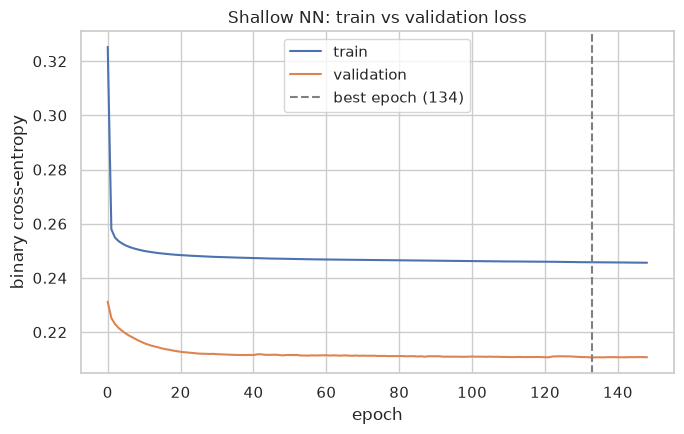

In [78]:
# 9.4 Training curve of the chosen model: train vs validation loss
best_epoch = int(np.argmin(nn_hist.history["val_loss"])) + 1

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(nn_hist.history["loss"], label="train")
ax.plot(nn_hist.history["val_loss"], label="validation")
ax.axvline(best_epoch - 1, color="grey", linestyle="--", label=f"best epoch ({best_epoch})")
ax.set_title("Shallow NN: train vs validation loss"); ax.set_xlabel("epoch"); ax.set_ylabel("binary cross-entropy")
ax.legend(); plt.tight_layout(); plt.show()

### 9.5 Model comparison

All models are scored on the same rows and features, with the same five metrics: ROC-AUC, PR-AUC, precision, recall and F1 (at the threshold chosen on validation). Each model stores its scores in `results[name]`, so the table below fills in as models are added.

**Primary metric: PR-AUC (average precision).** We calculate this using `average_precision_score`, rather than trapezoidal integration of the precision-recall curve. Podiums are about one row in seven. On a rare positive class, ROC-AUC can look high even when the top of the ranking is poor, because most of its credit comes from correctly ranking the many non-podium rows. PR-AUC only measures how well the model ranks true podium finishers above the rest, which is the question a podium predictor has to answer.

**Secondary metric: F1 (on the chosen threshold).** It turns the ranking into a yes/no decision, so it shows the precision-recall trade-off a user would actually act on. ROC-AUC is reported for context only.

**Selection rule:** the model with the best **validation** PR-AUC is the reference. The test set is only used to report the final numbers, not to pick a model. The table is read against the logistic regression baseline (9.1): a more complex model is only worth its extra complexity if it beats the baseline on PR-AUC.

**Random forest versus baseline (saved run):** random forest improves validation average precision from 0.7059 to 0.7254, but its test average precision is slightly lower than logistic regression (0.7079 versus 0.7102). These results do not demonstrate a clear test-performance advantage for the forest. Test results are reported, not used to choose the model.


In [79]:
# 9.5 Model comparison: one row per model and split, the five comparison metrics
splits = ["train", "validation", "test"]
comparison = pd.concat({name: pd.DataFrame({s: r[s] for s in splits if s in r}).T for name, r in results.items()},
                       names=["model", "split"])
comparison = comparison.reindex(columns=["ROC-AUC", "PR-AUC", "Precision", "Recall", "F1"])
comparison.round(4)


ROC-AUC  PR-AUC  Precision  Recall      F1
model               split                                                 
Logistic Regression train        0.8965  0.5612     0.5369  0.5926  0.5634
                    validation   0.9304  0.7059     0.6523  0.8107  0.7229
                    test         0.9337  0.7102     0.6281  0.7451  0.6816
Random Forest       train        0.9036  0.5886     0.6060  0.4695  0.5291
                    validation   0.9399  0.7254     0.7108  0.7284  0.7195
                    test         0.9408  0.7079     0.7049  0.6324  0.6667
Gradient Boosting   train        0.9034  0.5862     0.5725  0.5373  0.5543
                    validation   0.9363  0.7094     0.6856  0.7449  0.7140
                    test         0.9422  0.7093     0.6881  0.6814  0.6847
Shallow NN          train        0.9047  0.5781     0.5823  0.5088  0.5431
                    validation   0.9416  0.7333     0.6906  0.7531  0.7205
                    test         0.9369  0.6879     0.6935  0.6324  0.6615

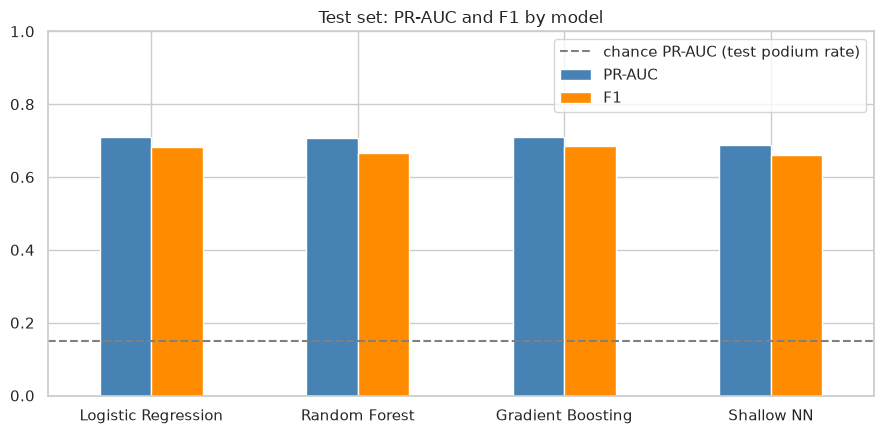

In [80]:
# 9.5 Plot: test-set PR-AUC and F1 per model, with the podium rate as the chance line
test_scores = comparison.xs("test", level="split")[["PR-AUC", "F1"]]
ax = test_scores.plot.bar(figsize=(9, 4.5), rot=0, color=["steelblue", "darkorange"])
ax.axhline(y_test.mean(), ls="--", color="grey", label="chance PR-AUC (test podium rate)")
ax.set_title("Test set: PR-AUC and F1 by model"); ax.set_xlabel(""); ax.set_ylim(0, 1)
ax.legend(loc="upper right"); plt.tight_layout(); plt.show()


**Model selection and XAI:** The highest validation average precision identifies the performance reference. Section 11 separately explains the random forest using TreeExplainer, permutation importance and LIME. The neural network leads in the saved comparison (0.7264 versus 0.7254); choosing the forest for XAI does not change that winner or establish statistical equivalence.


In [81]:
# 9.5 Check: is the model explained in Section 11 (random forest) the validation reference?
val_pr = comparison.xs("validation", level="split")["PR-AUC"].sort_values(ascending=False)
display(val_pr.to_frame("validation PR-AUC").round(4))
gap = val_pr.max() - val_pr["Random Forest"]
print(f"Best on validation PR-AUC: {val_pr.index[0]} | random forest is {gap:.4f} below the best")
print("Model explained in Section 11: Random Forest (chosen for detailed tree-based XAI)")


,validation PR-AUC
model,
Shallow NN,0.7333
Random Forest,0.7254
Gradient Boosting,0.7094
Logistic Regression,0.7059


Best on validation PR-AUC: Shallow NN | random forest is 0.0079 below the best
Model explained in Section 11: Random Forest (chosen for detailed tree-based XAI)


## 10. Feature-group ablation

An ablation removes **one feature group at a time**, retrains, and measures how much performance drops. This checks each group's real contribution after training, where Section 6 checked it before training.

Groups (from 6.2): **grid**, **qualifying**, **driver form**, **team form**, **standings**, **context**.

Report, for each group: the features removed, the retrained model's scores on validation and test, and the drop from the full model.

**Design.**
* **Models:** the tuned random forest (the model explained in Section 11) and the logistic-regression baseline, so we can see whether conclusions depend on the model type.
* **Fixed hyper-parameters:** the values chosen in 9.1 / 9.2 are kept; only the feature columns change, so any change in score comes from the removed group.
* **Threshold:** re-chosen on **validation F1** for every ablated model; the test set is only scored (never used for choices).
* **Noise:** the random forest is averaged over 3 seeds. Differences below about 0.005 PR-AUC are within noise.
* **Two views:** *leave one group out* (what is lost) and *keep only one group* (what a group can do alone). Because groups overlap, the second view is needed to read the first.


=== Random Forest (positive drop = the group helped) ===


,features left,val ROC-AUC,val PR-AUC,val F1,test ROC-AUC,test PR-AUC,test F1,val PR-AUC drop,test PR-AUC drop
full model (all groups),13,0.9399,0.7252,0.7205,0.9408,0.7094,0.6638,0.0000,0.0000
without grid,11,0.9343,0.7049,0.7152,0.9273,0.6757,0.6174,0.0203,0.0337
without qualifying,10,0.9393,0.7218,0.7279,0.9409,0.7166,0.6351,0.0034,-0.0072
without driver_form,11,0.9398,0.7216,0.7236,0.9415,0.7145,0.6666,0.0036,-0.0051
without team_form,12,0.9396,0.7249,0.7191,0.9405,0.7094,0.6762,0.0003,0.0000
without standings,10,0.9386,0.7213,0.7206,0.9376,0.7014,0.6916,0.0039,0.0080
without context,11,0.9399,0.7205,0.7216,0.9408,0.7054,0.6510,0.0047,0.0040



=== Logistic Regression (positive drop = the group helped) ===


,features left,val ROC-AUC,val PR-AUC,val F1,test ROC-AUC,test PR-AUC,test F1,val PR-AUC drop,test PR-AUC drop
full model (all groups),13,0.9304,0.7059,0.7229,0.9337,0.7102,0.6816,0.0000,0.0000
without grid,11,0.9290,0.6821,0.7171,0.9311,0.6868,0.6564,0.0238,0.0235
without qualifying,10,0.9289,0.6997,0.7196,0.9337,0.7032,0.6728,0.0063,0.0070
without driver_form,11,0.9306,0.7063,0.7166,0.9339,0.7139,0.6682,-0.0003,-0.0037
without team_form,12,0.9307,0.7070,0.7239,0.9324,0.7042,0.6885,-0.0011,0.0061
without standings,10,0.9294,0.7074,0.7266,0.9312,0.7044,0.6898,-0.0015,0.0058
without context,11,0.9304,0.7041,0.7229,0.9336,0.7094,0.6786,0.0019,0.0009


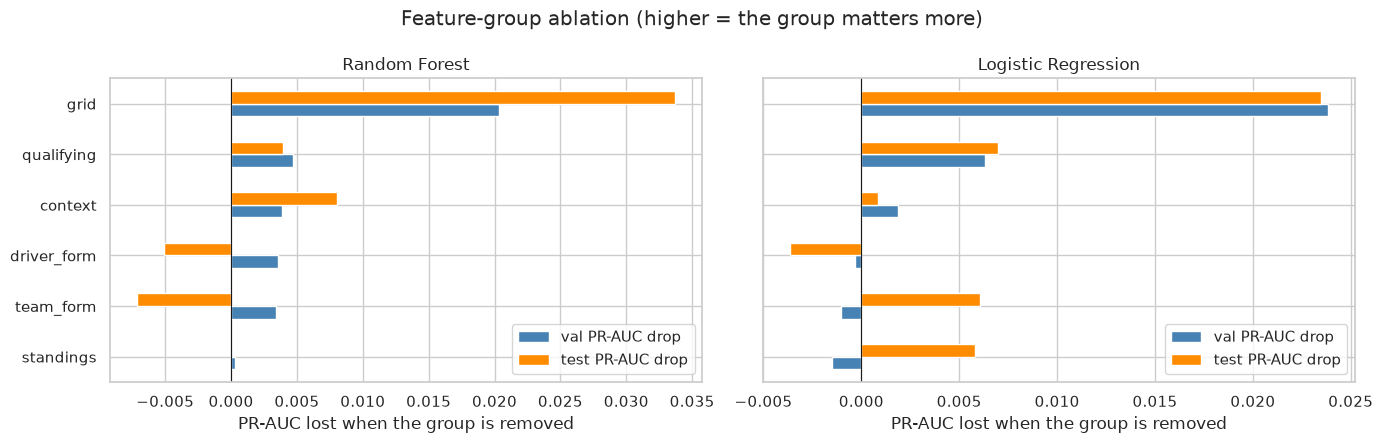


=== Random Forest: one group only ===


,val PR-AUC,test PR-AUC,val ROC-AUC,test ROC-AUC
only grid,0.6684,0.6473,0.9181,0.9137
only qualifying,0.6896,0.6455,0.9317,0.9204
only driver_form,0.6122,0.5500,0.9006,0.8800
only team_form,0.5358,0.4804,0.8893,0.8769
only standings,0.6282,0.5619,0.9023,0.8847
only context,0.2196,0.1438,0.6011,0.4957



=== Logistic Regression: one group only ===


,val PR-AUC,test PR-AUC,val ROC-AUC,test ROC-AUC
only grid,0.6684,0.6473,0.9178,0.9138
only qualifying,0.6876,0.6475,0.9247,0.9146
only driver_form,0.6085,0.5402,0.9026,0.8812
only team_form,0.5413,0.4804,0.8896,0.8769
only standings,0.6294,0.5587,0.8945,0.8776
only context,0.2032,0.1410,0.6162,0.4836


In [82]:
# 10 Feature-group ablation: remove one group at a time, retrain, compare with the full model
# Models: the tuned random forest (the model explained in Section 11) and the logistic-regression baseline.
# Hyper-parameters are kept fixed (the values chosen in 9.1 / 9.2); only the feature columns change.
# For every ablated model the threshold is re-chosen on validation F1; the test set is only scored.
rf_depth, rf_split, rf_leaf, rf_feat, rf_weight = best_key
ABL_SEEDS = [SEED, SEED + 1, SEED + 2]      # random forest is averaged over 3 seeds to reduce noise

def fit_score(model_name, cols, seed=SEED):
    idx = [FEATURES.index(c) for c in cols]
    if model_name == "Random Forest":
        m = RandomForestClassifier(n_estimators=300, max_depth=rf_depth, min_samples_split=rf_split,
                                   min_samples_leaf=rf_leaf, max_features=rf_feat, class_weight=rf_weight,
                                   random_state=seed, n_jobs=-1)
        A, B, C = Xtr_imp[:, idx], Xva_imp[:, idx], Xte_imp[:, idx]
    else:
        m = LogisticRegression(max_iter=2000)
        A, B, C = Xtr_sc[:, idx], Xva_sc[:, idx], Xte_sc[:, idx]
    m.fit(A, y_train)
    pv, pt = m.predict_proba(B)[:, 1], m.predict_proba(C)[:, 1]
    pr, rc, th = precision_recall_curve(y_val, pv)
    thr = th[(2 * pr[:-1] * rc[:-1] / np.maximum(pr[:-1] + rc[:-1], 1e-12)).argmax()]
    return {"val ROC-AUC": roc_auc_score(y_val, pv), "val PR-AUC": average_precision_score(y_val, pv),
            "val F1": f1_score(y_val, pv >= thr),
            "test ROC-AUC": roc_auc_score(y_test, pt), "test PR-AUC": average_precision_score(y_test, pt),
            "test F1": f1_score(y_test, pt >= thr)}

variants = {"full model (all groups)": FEATURES}
for g, feats in GROUPS.items():
    variants[f"without {g}"] = [f for f in FEATURES if f not in feats]

abl = {}
for model_name in ["Random Forest", "Logistic Regression"]:
    seeds = ABL_SEEDS if model_name == "Random Forest" else [SEED]
    rows = {}
    for label, cols in variants.items():
        rows[label] = pd.DataFrame([fit_score(model_name, cols, s) for s in seeds]).mean()
    t = pd.DataFrame(rows).T
    full = t.loc["full model (all groups)"]
    t.insert(0, "features left", [len(c) for c in variants.values()])
    t["val PR-AUC drop"] = full["val PR-AUC"] - t["val PR-AUC"]
    t["test PR-AUC drop"] = full["test PR-AUC"] - t["test PR-AUC"]
    abl[model_name] = t
    print(f"\n=== {model_name} (positive drop = the group helped) ===")
    display(t.round(4))

# plot: PR-AUC drop per removed group, validation vs test, for both models
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for ax, (model_name, t) in zip(axes, abl.items()):
    d = t.drop(index="full model (all groups)")[["val PR-AUC drop", "test PR-AUC drop"]]
    d.index = [i.replace("without ", "") for i in d.index]
    d.sort_values("val PR-AUC drop").plot.barh(ax=ax, color=["steelblue", "darkorange"])
    ax.axvline(0, c="k", lw=0.8); ax.set_title(model_name); ax.set_xlabel("PR-AUC lost when the group is removed")
plt.suptitle("Feature-group ablation (higher = the group matters more)"); plt.tight_layout(); plt.show()

# complementary view: keep ONLY one group (shows what each group can do alone; groups overlap, so drops above can be small)
alone = {}
for model_name in ["Random Forest", "Logistic Regression"]:
    seeds = ABL_SEEDS if model_name == "Random Forest" else [SEED]
    alone[model_name] = pd.DataFrame({f"only {g}": pd.DataFrame([fit_score(model_name, feats, s) for s in seeds]).mean()
                                      for g, feats in GROUPS.items()}).T[["val PR-AUC", "test PR-AUC", "val ROC-AUC", "test ROC-AUC"]]
    print(f"\n=== {model_name}: one group only ===")
    display(alone[model_name].round(4))

**Result (PR-AUC, random forest; positive drop = the group helped).** Full model: validation 0.725, test 0.709.

| removed group | val drop | test drop | reading |
|---|---|---|---|
| **grid** | **0.020** | **0.034** | the only group whose removal clearly hurts on both splits |
| qualifying | 0.003 | -0.007 | no loss: `grid_feat` already carries the same information |
| driver form | 0.004 | -0.005 | no loss |
| team form | 0.000 | 0.000 | no loss |
| standings | 0.004 | 0.008 | small loss |
| context | 0.005 | 0.004 | small loss, close to noise |

Logistic regression tells the same story: grid is again the largest drop (0.024 val, 0.024 test); qualifying (0.006, 0.007) and standings are small; driver form and team form are within noise.

**Keep-only-one-group (test PR-AUC, RF):** qualifying 0.646, grid 0.647, standings 0.562, driver form 0.550, team form 0.480, context 0.144 (about the podium rate, i.e. no better than chance). Grid and qualifying are each almost as good as the full model (0.709) alone.

**Interpretation.**
* **Grid** is the most important group, in agreement with the single-feature AUC chart in Section 6.
* **Qualifying, form and standings** are individually strong (second view) but **redundant** with each other and with grid: removing one is compensated by the others, so the leave-one-out drop is near zero. Not being needed does not make them wrong or leaky; it means the information is shared.
* **Context** (age, `home_race`) is weak alone and adds almost nothing, which matches Q2 (no home advantage). We keep it because it costs nothing, but it could be dropped without a visible change.
* Test drops for qualifying and driver form are *negative*: the model is slightly better on the 2022-2024 test seasons without them. This is a small, single-split effect and we do not treat it as evidence to remove them, since validation shows a small positive contribution.
* **Limits:** one time-based split (test = 2022-2024 only, ~1,300 rows), correlated features, and importance in the model is not causal importance of the factor in the real race.


## 11. Explainability (XAI)

We explain the fitted random forest using **permutation importance and SHAP globally**, and **LIME for one driver-race prediction**. The forest is trained on **1950-2017**, with validation explanations based on **2018-2021**. Preprocessing remains fitted on training data. The interpretations below match the current 1950-onward dataset, rather than the earlier 2003-onward training dataset.

**Why explain the forest?** In the saved comparison, the neural network has the highest validation average precision (0.7264), closely followed by the random forest (0.7254). We use the forest for detailed XAI because it supports efficient TreeExplainer explanations. This does not make it the highest-scoring validation model or establish statistical equivalence with the neural network.

Feature importance describes model reliance, **not causal effects on podium finishes**.


### 11.1 Global: permutation importance

Original validation PR-AUC (average precision): 0.7254


,feature,mean PR-AUC drop,std across shuffles
0,grid_feat,0.2115,0.0294
1,quali_gap_pct,0.0131,0.0090
2,drv_points_share,0.0113,0.0121
3,drv_podiums_last5,0.0098,0.0080
4,drv_champ_pos,0.0081,0.0073
5,quali_pos,0.0050,0.0081
6,team_podiums_last5,0.0028,0.0077
7,team_champ_pos,0.0021,0.0052
8,drv_avg_finish_last5,0.0018,0.0055
9,driver_age,0.0014,0.0029


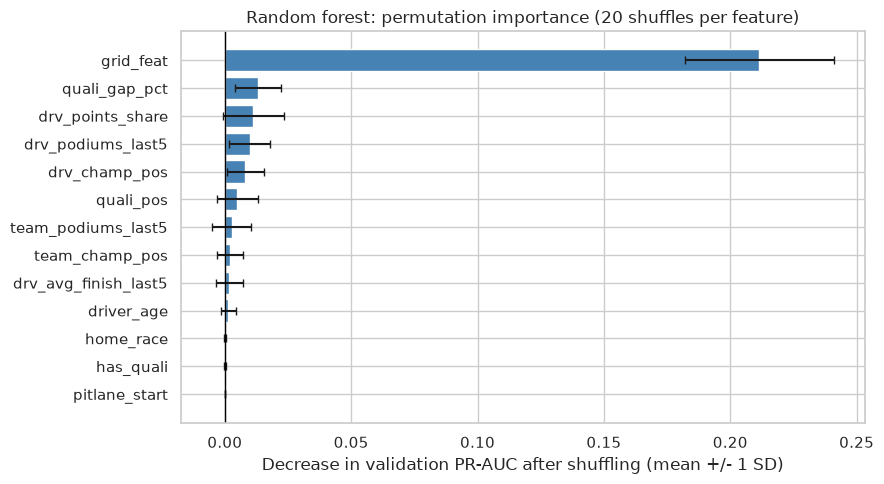

In [83]:
# 11.1 Random forest: permutation importance on validation data
from sklearn.inspection import permutation_importance
from IPython.display import display

# Use the same imputed, unscaled features used to train rf.
# The fitted model and preprocessing are not changed or re-fitted.
baseline_ap = average_precision_score(y_val, rf.predict_proba(Xva_imp)[:, 1])
perm_result = permutation_importance(
    rf, Xva_imp, y_val,
    scoring="average_precision",  # same PR-AUC measure as Section 9
    n_repeats=20,
    random_state=SEED,
    n_jobs=-1,
)

perm_table = pd.DataFrame({
    "feature": FEATURES,
    "mean PR-AUC drop": perm_result.importances_mean,
    "std across shuffles": perm_result.importances_std,
}).sort_values("mean PR-AUC drop", ascending=False).reset_index(drop=True)

print(f"Original validation PR-AUC (average precision): {baseline_ap:.4f}")
display(perm_table.round(4))

plot_table = perm_table.sort_values("mean PR-AUC drop")
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(
    plot_table["feature"], plot_table["mean PR-AUC drop"],
    xerr=plot_table["std across shuffles"],
    color="steelblue", capsize=3,
)
ax.axvline(0, color="black", linewidth=1)
ax.set_xlabel("Decrease in validation PR-AUC after shuffling (mean +/- 1 SD)")
ax.set_title("Random forest: permutation importance (20 shuffles per feature)")
plt.tight_layout()
plt.show()


**Reading permutation importance:** each feature is shuffled 20 times without retraining. A larger mean validation PR-AUC (average precision) drop indicates greater reliance. Error bars show one standard deviation across shuffles, not confidence intervals.

**Results for the current training dataset:** grid position has the largest mean drop (**0.2115**), followed by qualifying gap (**0.0131**), driver points share (**0.0113**), recent driver podium rate (**0.0098**), and driver championship position (**0.0081**). Qualifying position has a smaller drop (**0.0050**). Most non-grid drops are small relative to their shuffle variability. Home race and qualifying availability each have a drop of about 0.0001, and pit-lane start rounds to zero; this does not prove universal irrelevance.

Correlated features can substitute for one another, and shuffling can create unusual combinations. These results describe the fitted model on validation races and do not prove causation. Unlike ablation, permutation importance does not retrain the model, so their drop magnitudes need not agree.


### 11.1b Check: do the other models rely on the same features?

We explain the forest in detail, so we check that its explanation is not specific to it. The same permutation test is applied to gradient boosting and the shallow neural network, using identical shuffles.


,Random forest,Gradient boosting,Shallow NN
grid_feat,0.2169,0.2025,0.1057
quali_gap_pct,0.0141,0.0195,0.0157
drv_podiums_last5,0.0087,-0.0019,0.0225
drv_points_share,0.0070,0.0078,0.0248
drv_champ_pos,0.0066,0.0041,-0.0006
team_podiums_last5,0.0038,0.0040,0.0067
drv_avg_finish_last5,0.0035,-0.0030,0.0058
team_champ_pos,0.0027,0.0016,0.0031
driver_age,0.0019,-0.0012,0.0034
quali_pos,0.0017,0.0019,0.0750


Rank of each feature (1 = largest PR-AUC drop):


,Random forest,Gradient boosting,Shallow NN
grid_feat,1,1,1
quali_gap_pct,2,2,5
drv_podiums_last5,3,12,4
drv_points_share,4,3,3
drv_champ_pos,5,4,13
team_podiums_last5,6,5,6
drv_avg_finish_last5,7,13,7
team_champ_pos,8,7,9
driver_age,9,11,8
quali_pos,10,6,2


Spearman rank correlation, random forest vs Gradient boosting: 0.52
Spearman rank correlation, random forest vs Shallow NN: 0.59


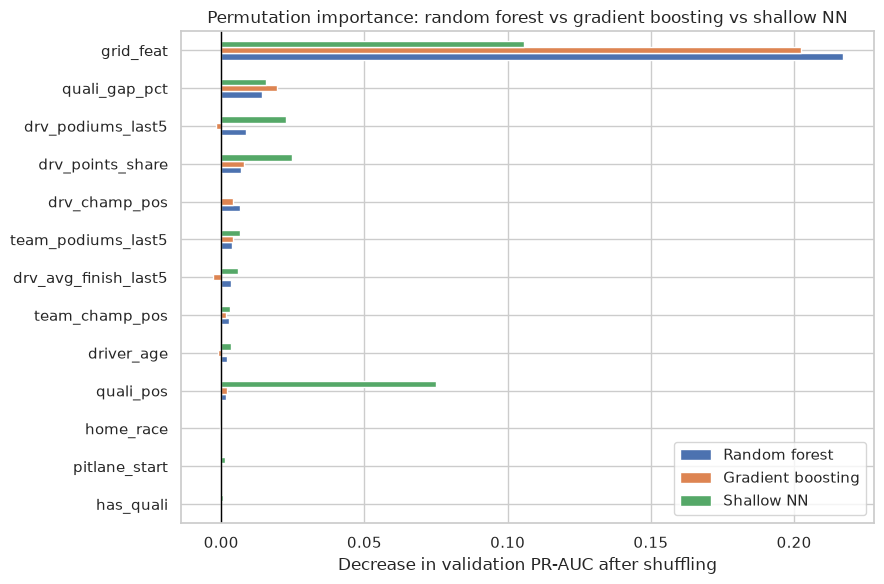

In [84]:
# 11.1b Do the other models rely on the same features? Permutation importance on validation data
# Same metric, same 20 repeats and the same shuffled row orders for every model. Each model keeps the
# input it was trained on: imputed for the forest and boosting, imputed + scaled for the neural network.
perm_inputs = {
    "Random forest": (lambda X: rf.predict_proba(X)[:, 1], Xva_imp),
    "Gradient boosting": (lambda X: gb.predict_proba(X)[:, 1], Xva_imp),
    "Shallow NN": (lambda X: nn.predict(X, verbose=0).ravel(), Xva_sc),
}
rng_perm = np.random.RandomState(SEED)
perm_orders = [[rng_perm.permutation(len(y_val)) for _ in range(20)] for _ in FEATURES]

perm_compare = {}
for model_name, (predict, X_in) in perm_inputs.items():
    base = average_precision_score(y_val, predict(X_in))
    drops = []
    for j in range(len(FEATURES)):
        d = []
        for order in perm_orders[j]:
            X_shuf = X_in.copy()
            X_shuf[:, j] = X_in[order, j]
            d.append(base - average_precision_score(y_val, predict(X_shuf)))
        drops.append(np.mean(d))
    perm_compare[model_name] = pd.Series(drops, index=FEATURES)

perm_compare = pd.DataFrame(perm_compare).sort_values("Random forest", ascending=False)
display(perm_compare.round(4))
print("Rank of each feature (1 = largest PR-AUC drop):")
perm_ranks = perm_compare.rank(ascending=False, method="min").astype(int)
display(perm_ranks)

from scipy.stats import spearmanr
for other in ["Gradient boosting", "Shallow NN"]:
    rho = spearmanr(perm_compare["Random forest"], perm_compare[other])[0]
    print(f"Spearman rank correlation, random forest vs {other}: {rho:.2f}")

ax = perm_compare.sort_values("Random forest").plot.barh(figsize=(9, 6))
ax.axvline(0, color="black", linewidth=1)
ax.set_xlabel("Decrease in validation PR-AUC after shuffling")
ax.set_title("Permutation importance: random forest vs gradient boosting vs shallow NN")
plt.tight_layout(); plt.show()


**Reading the cross-model check:** all three models put grid position first by a wide margin (forest 0.2169, gradient boosting 0.2025, neural network 0.1057 PR-AUC drop). Past that, agreement is only moderate: Spearman rank correlations with the forest are **0.52** (gradient boosting) and **0.59** (neural network), over 13 features. The forest's explanation is therefore representative of the main finding, that the starting grid dominates, but not of the exact order of the weaker features.

The clearest disagreement is qualifying position. The neural network loses 0.0750 when it is shuffled (rank 2), while the forest loses 0.0017 (rank 10). A plausible reason is that the forest can use grid position and qualifying gap in place of it, but we did not test this. Several small features, such as recent driver podium rate and average finish, have drops near zero or slightly negative for gradient boosting, so their ranks there are not meaningful.

These forest values differ slightly from Section 11.1 (for example 0.2169 vs 0.2115 for grid position) because this cell uses a different set of 20 shuffles shared by all three models. Like Section 11.1, this describes what each fitted model relies on, **not causal effects**, and correlated features can share credit.

### 11.2 Global: SHAP

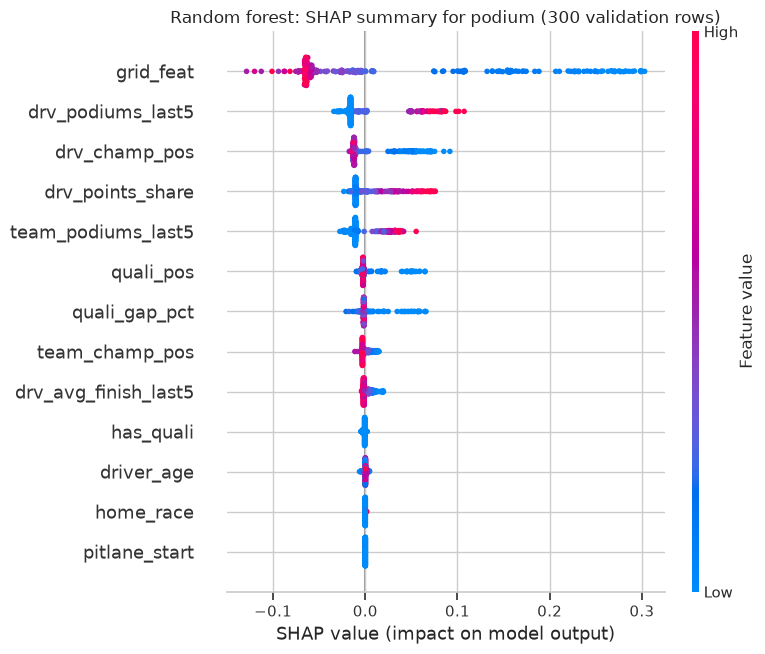

,Mean absolute SHAP
grid_feat,0.0899
drv_podiums_last5,0.0256
drv_champ_pos,0.0222
drv_points_share,0.0185
team_podiums_last5,0.0168
quali_pos,0.0073
quali_gap_pct,0.0062
team_champ_pos,0.0044
drv_avg_finish_last5,0.0036
has_quali,0.0015


**Results:** the largest average absolute contributions in this validation sample are **grid_feat** (0.0899), **drv_podiums_last5** (0.0256), **drv_champ_pos** (0.0222). Read the dot positions to see direction; the ranking measures magnitude.

In [85]:
# 11.2 Global SHAP: random forest on a validation sample
import shap
from IPython.display import display, Markdown

# Use imputed, unscaled inputs, as in random forest training.
X_val_xai = pd.DataFrame(Xva_imp, columns=FEATURES)
X_train_xai = pd.DataFrame(Xtr_imp, columns=FEATURES)
podium_class = int(np.flatnonzero(rf.classes_ == 1)[0])

# A reproducible random sample covers validation seasons without using test data.
X_shap = X_val_xai.sample(n=min(300, len(X_val_xai)), random_state=SEED)

explainer = shap.TreeExplainer(rf)
shap_values = explainer.shap_values(X_shap)
# Older SHAP returns a list per class; newer SHAP returns a 3D array.
if isinstance(shap_values, list):
    shap_values_podium = shap_values[podium_class]
else:
    shap_values_podium = shap_values[:, :, podium_class]

shap.summary_plot(
    shap_values_podium, X_shap, feature_names=FEATURES, show=False)
plt.title(f"Random forest: SHAP summary for podium ({len(X_shap)} validation rows)")
plt.tight_layout()
plt.show()

shap_ranking = pd.Series(
    np.abs(shap_values_podium).mean(axis=0), index=FEATURES,
    name="Mean absolute SHAP").sort_values(ascending=False)
display(shap_ranking.to_frame().round(4))
display(Markdown(
    "**Results:** the largest average absolute contributions in this validation sample are "
    + ", ".join(f"**{f}** ({v:.4f})" for f, v in shap_ranking.head(3).items())
    + ". Read the dot positions to see direction; the ranking measures magnitude."))


**Reading SHAP:** each dot is one validation prediction. Positive values raise podium probability relative to the explainer baseline; negative values lower it. Red means a higher feature value and blue a lower value. Features are ordered by average absolute contribution; a low grid number means a better start.

**Results for the current training dataset:** grid position has the largest mean absolute SHAP contribution (**0.0899**), followed by recent driver podium rate (**0.0256**) and driver championship position (**0.0222**). In the saved plot, low grid numbers (blue) generally push predictions toward podium, while higher grid numbers generally lower them. Higher recent podium rates and points shares generally raise the prediction; lower championship-position numbers also tend to raise it. These are patterns in this sample, not rules that hold for every driver-race.

The summary uses 300 randomly sampled validation rows. Driver age, home race and pit-lane start have small or near-zero contributions in this sample. Correlated features may share credit, and the sample does not represent every race. SHAP contribution magnitudes and permutation PR-AUC drops measure different quantities and need not have identical rankings. SHAP explains predictions, not causation.


,Selected driver-race
year,2019
race_name,Mexican Grand Prix
forename,Valtteri
surname,Bottas
raceId,1027
driverId,822


,Original value,Imputed input
grid_feat,6.000000,6.000000
pitlane_start,0.000000,0.000000
quali_pos,6.000000,6.000000
quali_gap_pct,0.775837,0.775837
has_quali,1.000000,1.000000
drv_podiums_last5,0.800000,0.800000
drv_avg_finish_last5,2.600000,2.600000
team_podiums_last5,1.600000,1.600000
drv_points_share,0.810651,0.810651
drv_champ_pos,2.000000,2.000000


Forest podium probability: 0.449177292189
Validation-selected threshold: 0.449177292189
Probability minus threshold: +0.000000000000e+00
Decision: Podium
Actual outcome (comparison only): Podium


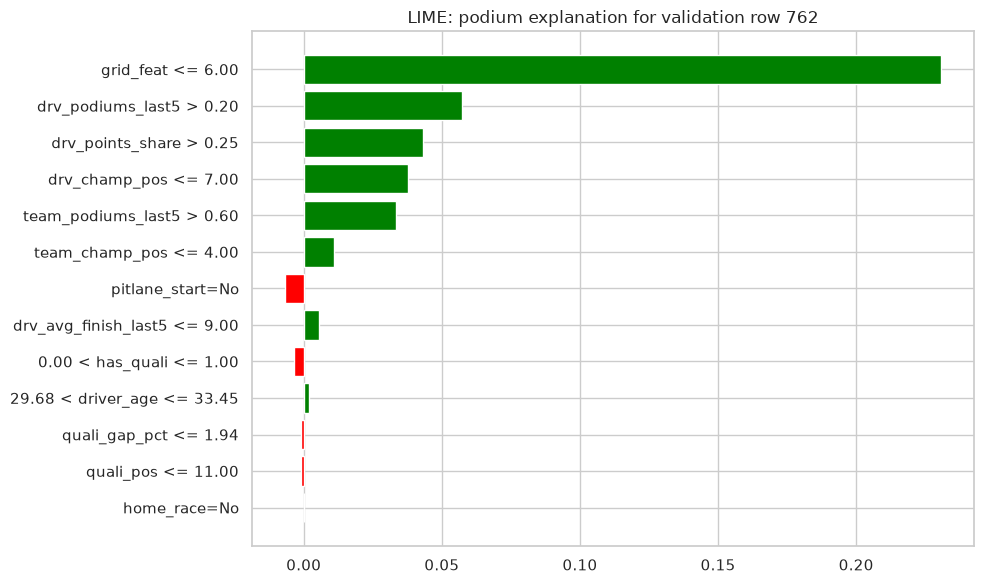

,Feature condition,Local weight
0,grid_feat <= 6.00,0.2308
1,drv_podiums_last5 > 0.20,0.0573
2,drv_points_share > 0.25,0.0432
3,drv_champ_pos <= 7.00,0.0376
4,team_podiums_last5 > 0.60,0.0334
5,team_champ_pos <= 4.00,0.0111
6,pitlane_start=No,-0.0068
7,drv_avg_finish_last5 <= 9.00,0.0054
8,0.00 < has_quali <= 1.00,-0.0034
9,29.68 < driver_age <= 33.45,0.0019


LIME approximate probability: 0.4393
Absolute difference from forest: 0.0099
LIME local weighted R-squared: 0.8603


**Local LIME results:** the strongest supporting conditions are `grid_feat <= 6.00` (+0.2308); `drv_podiums_last5 > 0.20` (+0.0573); the strongest opposing conditions are `pitlane_start=No` (-0.0068); `0.00 < has_quali <= 1.00` (-0.0034). The approximation predicts 0.439, compared with forest probability 0.449, with local weighted R-squared 0.860. A large probability difference or low R-squared limits this explanation.

In [86]:
# 11.3 Local LIME
import lime.lime_tabular
from IPython.display import display, Markdown, HTML

# Choose a borderline case by prediction alone, without using its outcome.
X_val_xai = pd.DataFrame(Xva_imp, columns=FEATURES)
X_train_xai = pd.DataFrame(Xtr_imp, columns=FEATURES)
podium_class = int(np.flatnonzero(rf.classes_ == 1)[0])
p_val_xai = rf.predict_proba(X_val_xai.to_numpy())[:, podium_class]
i = int(np.argmin(np.abs(p_val_xai - threshold_rf)))
local_record = val.iloc[i]
identity_cols = [c for c in ["year", "race_name", "forename", "surname", "raceId", "driverId"] if c in val.columns]
display(local_record[identity_cols].to_frame("Selected driver-race"))
display(pd.DataFrame({"Original value": X_val.iloc[i].to_numpy(),
                      "Imputed input": X_val_xai.iloc[i].to_numpy()}, index=FEATURES))
p_local = float(p_val_xai[i])  # reuse the same batch probability used to select the case
print(f"Forest podium probability: {p_local:.12f}")
print(f"Validation-selected threshold: {threshold_rf:.12f}")
print(f"Probability minus threshold: {p_local - threshold_rf:+.12e}")
print("Decision:", "Podium" if p_local >= threshold_rf else "No podium")
print("Actual outcome (comparison only):", "Podium" if y_val[i] == 1 else "No podium")

# LIME uses training inputs to define its reference distributions.
binary_cols = [FEATURES.index(f) for f in ["home_race", "pitlane_start"] if f in FEATURES]
explainer_lime = lime.lime_tabular.LimeTabularExplainer(
    X_train_xai.values,
    feature_names=FEATURES,
    class_names=["Podium" if c == 1 else "No podium" for c in rf.classes_],
    categorical_features=binary_cols,
    categorical_names={j: ["No", "Yes"] for j in binary_cols},
    mode="classification", discretize_continuous=True, random_state=SEED)
exp = explainer_lime.explain_instance(
    X_val_xai.values[i], rf.predict_proba,
    labels=(podium_class,), num_features=len(FEATURES), num_samples=5000)
# Display the interactive explanation in the notebook.
display(HTML(exp.as_html(labels=(podium_class,))))
# Static version stays visible in notebook exports and the report.
fig = exp.as_pyplot_figure(label=podium_class)
fig.set_size_inches(10, 6)
plt.title(f"LIME: podium explanation for validation row {i}")
plt.tight_layout()
plt.show()

lime_table = pd.DataFrame(exp.as_list(label=podium_class),
                          columns=["Feature condition", "Local weight"])
display(lime_table.round(4))
p_approx = float(np.asarray(exp.local_pred).ravel()[0])
print(f"LIME approximate probability: {p_approx:.4f}")
print(f"Absolute difference from forest: {abs(p_local - p_approx):.4f}")
print(f"LIME local weighted R-squared: {exp.score:.4f}")
positive = lime_table[lime_table["Local weight"] > 0].nlargest(2, "Local weight")
negative = lime_table[lime_table["Local weight"] < 0].nsmallest(2, "Local weight")
def describe_terms(table):
    return "; ".join(f"`{r['Feature condition']}` ({r['Local weight']:+.4f})" for _, r in table.iterrows()) or "none"
display(Markdown(
    f"**Local LIME results:** the strongest supporting conditions are {describe_terms(positive)}; "
    f"the strongest opposing conditions are {describe_terms(negative)}. "
    f"The approximation predicts {p_approx:.3f}, compared with forest probability {p_local:.3f}, "
    f"with local weighted R-squared {exp.score:.3f}. A large probability difference or low R-squared limits this explanation."))


**Interpreting the saved local example:** Bottas at the 2019 Mexican Grand Prix was chosen because his forest probability is closest to the validation-selected threshold, without using his actual outcome to choose him. LIME's strongest supporting conditions are starting within the top six (+0.2308) and a recent podium rate above 0.20 (+0.0573). These are coefficients of a local approximation, not causal effects or the forest's own SHAP contributions.

The saved LIME approximation predicts 0.4393 versus a forest probability of about 0.4492, an absolute difference of 0.0099 (0.99 percentage points). Its local weighted R-squared is 0.8603, indicating a reasonably close fit to the sampled neighbourhood, not a guarantee of reliability. The precise probability, threshold and their difference are printed above to make this borderline decision clear. Bottas actually finished on the podium; the actual outcome is shown only for comparison.

LIME perturbs features to fit a simpler local model. Because grid, qualifying and form features are related, some perturbed combinations may be unrealistic. The explanation applies locally to this prediction and does not establish causation.


## 12. Inference function

One function that takes a driver-race record as input and returns the podium probability and the podium/not-podium decision, using the chosen model and the threshold from validation.

Demonstrate it on:
1. a **complete** record (all features present), and
2. a **partially-missing** record (some features set to missing, to show the imputer handles them).

**Chosen model:** the tuned random forest `rf` from 9.2 (the model explained in Section 11), with its validation-F1 threshold `threshold_rf`. The function reuses the **already fitted** median `imputer` from Section 8; nothing is re-fitted, so inference sees exactly the same pipeline as training. The forest was trained on imputed, *unscaled* inputs, so the scaler is not applied.

The record can be a `dict`, a `pd.Series` or a one-row `pd.DataFrame`. Any feature that is absent or `None`/`NaN` is filled with the training median; extra columns (names, ids) are ignored. The function also reports which features were imputed, so the caller knows how much of the input was filled in rather than observed.

### 12.1 Inference function

In [87]:
# 12.1 Inference function: chosen model (random forest) + validation threshold + train-fitted imputer
def predict_podium(record, model=rf, threshold=threshold_rf):
    """Return the podium probability and decision for one driver-race record.

    record: dict, pd.Series or one-row pd.DataFrame with (some of) the FEATURES.
    Missing or NaN features are filled by the median imputer fitted on train only.
    """
    if isinstance(record, pd.DataFrame):
        if len(record) != 1:
            raise ValueError("pass exactly one driver-race record")
        record = record.iloc[0]
    record = pd.Series(record, dtype=object)
    # keep only model features, in training order; absent features become NaN
    row = pd.DataFrame([record.reindex(FEATURES)], columns=FEATURES).apply(pd.to_numeric, errors="coerce")
    imputed = [f for f in FEATURES if pd.isna(row.at[0, f])]
    X = imputer.transform(row)  # same transform as training; no re-fit, no scaling for the forest
    podium_class = int(np.flatnonzero(model.classes_ == 1)[0])
    p = float(model.predict_proba(X)[0, podium_class])
    return {"podium_probability": p,
            "threshold": float(threshold),
            "prediction": "Podium" if p >= threshold else "No podium",
            "imputed_features": imputed,
            "model_input": pd.Series(X[0], index=FEATURES)}

def show_prediction(out, title):
    print(title)
    print(f"  podium probability : {out['podium_probability']:.4f}")
    print(f"  threshold          : {out['threshold']:.4f}")
    print(f"  decision           : {out['prediction']}")
    print(f"  imputed features   : {out['imputed_features'] or 'none'}")

### 12.2 Demo: complete record

In [88]:
# 12.2 Demo on a complete record: first test-set row with every feature present
complete_idx = test.index[test[FEATURES].notna().all(axis=1)][0]
complete_record = test.loc[complete_idx]
id_cols = [c for c in ["year", "race_name", "forename", "surname"] if c in test.columns]
display(complete_record[id_cols + FEATURES].to_frame("Complete record"))

out_complete = predict_podium(complete_record.to_dict())
show_prediction(out_complete, "Complete record")
print("  actual outcome     :", "Podium" if complete_record["podium"] == 1 else "No podium", "(comparison only)")

# sanity check: same probability as the batch pipeline used for evaluation
p_batch = rf.predict_proba(prep(test.loc[[complete_idx], FEATURES], False))[0, list(rf.classes_).index(1)]
print(f"  batch-pipeline prob: {p_batch:.4f}  (match: {np.isclose(p_batch, out_complete['podium_probability'])})")

,Complete record
year,2022
race_name,Saudi Arabian Grand Prix
forename,Max
surname,Verstappen
grid_feat,4
pitlane_start,0
quali_pos,4.0
quali_gap_pct,0.295918
has_quali,1
drv_podiums_last5,0.8


Complete record
  podium probability : 0.4420
  threshold          : 0.4492
  decision           : No podium
  imputed features   : none
  actual outcome     : Podium (comparison only)
  batch-pipeline prob: 0.4420  (match: True)


### 12.3 Demo: partially-missing record

In [89]:
# 12.3 Demo on a partially-missing record: same driver-race, but qualifying data unknown,
# one form value set to None and driver_age left out of the input entirely
partial_record = {f: complete_record[f] for f in FEATURES if f != "driver_age"}
partial_record.update({"quali_pos": np.nan, "quali_gap_pct": np.nan, "drv_avg_finish_last5": None})

out_partial = predict_podium(partial_record)
show_prediction(out_partial, "Partially-missing record")

display(pd.DataFrame({"Given value": pd.Series(partial_record, dtype=object).reindex(FEATURES),
                      "Model input (after imputation)": out_partial["model_input"],
                      "Complete-record input": out_complete["model_input"]}))
print(f"Probability change vs complete record: "
      f"{out_partial['podium_probability'] - out_complete['podium_probability']:+.4f}")

Partially-missing record
  podium probability : 0.4041
  threshold          : 0.4492
  decision           : No podium
  imputed features   : ['quali_pos', 'quali_gap_pct', 'drv_avg_finish_last5', 'driver_age']


,Given value,Model input (after imputation),Complete-record input
grid_feat,4,4.000000,4.000000
pitlane_start,0,0.000000,0.000000
quali_pos,NaN,11.000000,4.000000
quali_gap_pct,NaN,1.943065,0.295918
has_quali,1,1.000000,1.000000
drv_podiums_last5,0.8,0.800000,0.800000
drv_avg_finish_last5,None,12.200000,5.200000
team_podiums_last5,0.8,0.800000,0.800000
drv_points_share,0.0,0.000000,0.000000
drv_champ_pos,19.0,19.000000,19.000000


Probability change vs complete record: -0.0379


**Reading the two demos.** The complete record goes through exactly the batch pipeline used for evaluation, which the check in 12.2 confirms by matching probabilities. In the partially-missing record, qualifying position, qualifying gap and recent average finish are replaced with their **training medians**, and `driver_age`, which is not passed at all, is imputed the same way. The function lists every imputed feature, so the caller can see how much of the input was filled in. The probability change shows how much the forest relied on the removed values. Median imputation pulls a record towards a "typical" driver, so a strong driver usually loses probability and a weak one gains some. A prediction with many imputed features should be trusted less.